# Cointegración y Modelo Vectorial de Corrección del Error (VECM)
## Guía de aprendizaje con aplicación a precios de petróleo crudo y gasóleo de calefacción

| Campo | Detalle |
|---|---|
| **Área** | Series de tiempo multivariadas · Econometría aplicada |
| **Nivel** | Maestría en Analítica de Datos |
| **Herramientas** | Python 3, `pandas`, `numpy`, `statsmodels`, `scipy`, `matplotlib`, `seaborn` |
| **Datos** | Futuros NYMEX de petróleo crudo WTI (`CL=F`) y gasóleo de calefacción (`HO=F`), cierres diarios congelados en `datos_vecm.csv` |
| **Período de análisis** | Enero 2015 – diciembre 2024, frecuencia mensual (último cierre de cada mes) |
| **Versión** | Reestructuración del cuaderno `15_cointegracion_vecm.ipynb` (ver `Informe_Mejoras_VECM.md`) |

> **Cómo usar este cuaderno.** Ejecútelo de arriba hacia abajo. Cada módulo sigue la secuencia
> *pregunta económica → intuición → visualización → matemática → código → resultados → interpretación → ejercicio*.
> Las interpretaciones escritas fueron contrastadas con las salidas que produce el archivo de datos congelado;
> si cambia los datos, vuelva a leer las salidas antes de aceptar cualquier conclusión del texto.

### Mapa del cuaderno

| Módulo | Tema | Pregunta que responde |
|---|---|---|
| 0 | Configuración | ¿Qué necesito para ejecutar el cuaderno? |
| 1 | Problema económico | ¿Por qué esperar una relación de largo plazo entre crudo y gasóleo? |
| 2 | Cointegración con datos simulados | ¿Qué es la cointegración y por qué la correlación no basta? |
| 3 | Del VAR al VECM | ¿Cómo se pasa de un VAR a un modelo con corrección del error? |
| 4 | Datos reales | ¿Qué datos usamos y cómo se preparan? |
| 5 | Estacionariedad | ¿Las series son I(1)? ¿Qué tan seguros estamos? |
| 6 | Rezagos y Johansen | ¿Cuántos rezagos y cuántas relaciones de cointegración? |
| 7 | Estimación del VECM | ¿Qué dicen β, α y Γ? |
| 8 | Diagnóstico | ¿El modelo está bien especificado? ¿Qué tan robusto es? |
| 9 | Análisis dinámico | ¿Qué ocurre tras un choque? (IRF y FEVD) |
| 10 | Pronóstico y validación | ¿Pronostica mejor que alternativas simples? |
| 11 | Discusión económica | ¿Qué podemos concluir y qué no? |
| 12 | Actividades | Ejercicios progresivos y actividad integradora |

---
## Módulo 0. Configuración del entorno

**Objetivo de aprendizaje:** dejar el entorno listo y documentado para que cualquier persona obtenga los mismos resultados.

El cuaderno no necesita internet: el caso base lee `datos_vecm.csv`, que debe estar en la misma carpeta.
La descarga desde Yahoo Finance se conserva como opción complementaria (Módulo 4). Las dependencias están en
`requirements.txt` (`pip install -r requirements.txt`).

In [1]:
# --- Librerías ---------------------------------------------------------------
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy
from scipy import stats
import statsmodels
from statsmodels.tsa.stattools import adfuller, kpss, coint
from statsmodels.tsa.api import VAR
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, select_coint_rank, coint_johansen
from statsmodels.stats.diagnostic import het_arch
from statsmodels.tools.sm_exceptions import InterpolationWarning
from IPython.display import display

# Silenciamos solo avisos conocidos e inofensivos (no todos los avisos):
# KPSS informa cuando el p-valor cae fuera de su tabla (lo tratamos explícitamente más abajo).
warnings.filterwarnings("ignore", category=InterpolationWarning)
warnings.filterwarnings("ignore", message=".*frequency information.*")
# coint_johansen convierte internamente autovalores reales almacenados como complejos (parte imaginaria nula)
warnings.filterwarnings("ignore", category=np.exceptions.ComplexWarning)

# --- Reproducibilidad ----------------------------------------------------------
SEMILLA = 2024
rng = np.random.default_rng(SEMILLA)

# --- Estilo gráfico coherente ---------------------------------------------------
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 100, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10.5, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8,
})
# Colores fijos por entidad (la misma variable siempre lleva el mismo color)
COL = {"CL": "#2a78d6", "HO": "#eb6834", "ECT": "#6250d6",
       "VECM": "#2a78d6", "VAR_dif": "#eb6834", "VAR_niv": "#1baf7a", "Ingenuo": "#7a7974",
       "obs": "#222222", "ref": "#9a9994"}
ETIQ = {"ln_CL": "ln(crudo WTI)", "ln_HO": "ln(gasóleo)"}

def eje_fechas(ax, paso_anios=1):
    # Ejes temporales legibles: un tick por año
    ax.xaxis.set_major_locator(mdates.YearLocator(paso_anios))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

print(f"Python      : {__import__('sys').version.split()[0]}")
for lib in (np, pd, scipy, statsmodels, matplotlib, sns):
    print(f"{lib.__name__:<12}: {lib.__version__}")

Python      : 3.13.18
numpy       : 2.5.3
pandas      : 2.3.3
scipy       : 1.18.1
statsmodels : 0.14.5
matplotlib  : 3.11.2
seaborn     : 0.13.2


> **Nota de versiones.** El cuaderno se verificó con `statsmodels` 0.14.5 y `pandas` 2.3.3. Las funciones
> usadas (`select_order`, `select_coint_rank`, `VECM.fit`, `test_whiteness`, `test_normality`, `irf`, `predict`)
> existen con esa firma en la serie 0.14. Si su versión difiere y algo falla, revise primero la documentación oficial
> de `statsmodels.tsa.vector_ar.vecm`.

---
## Módulo 1. Problema económico y motivación

**Objetivo de aprendizaje:** formular la pregunta económica antes de tocar cualquier prueba estadística.

### 1.1 ¿Por qué estos dos precios deberían estar relacionados?

El gasóleo de calefacción (*heating oil*, ULSD en la actualidad) se obtiene refinando petróleo crudo. El crudo es,
por tanto, el principal costo de producción del gasóleo. La diferencia entre el valor de los productos refinados
y el del crudo —el **margen de refinación** o *crack spread*— remunera a las refinerías. Si ese margen se vuelve
inusualmente alto, las refinerías tienen incentivos para procesar más crudo (lo que presiona al alza la demanda de crudo
y a la baja el precio del gasóleo); si se vuelve muy bajo, ocurre lo contrario. Además, los operadores de mercados
de futuros pueden tomar posiciones sobre el diferencial cuando se aleja de lo habitual.

Ese argumento no dice que los precios se muevan *igual* cada mes —el gasóleo tiene choques propios: inviernos fríos,
inventarios de destilados, paradas de refinerías—, sino que **no pueden alejarse indefinidamente uno del otro**.

### 1.2 Equilibrio de largo plazo frente a movimientos de corto plazo

- **Corto plazo:** variaciones mes a mes, ruidosas, influidas por choques específicos de cada mercado.
- **Largo plazo:** una relación de equilibrio, por ejemplo $\ln CL_t \approx \mu + b\,\ln HO_t$, alrededor de la cual
  los precios fluctúan. El **desequilibrio** $\ln CL_t - \mu - b\ln HO_t$ debería ser transitorio.

En econometría, "equilibrio" no significa que los precios estén quietos: significa que existe una combinación de ellos
que no se aleja sistemáticamente de un valor central.

### 1.3 Preguntas que guían el análisis

1. ¿Existe evidencia estadística de una relación estable de largo plazo entre ambos precios?
2. Si existe, ¿cuál es su forma y qué precio corrige los desequilibrios?
3. ¿Cómo se propaga un choque en un mercado hacia el otro?
4. ¿Ayuda esa estructura a pronosticar mejor que alternativas simples?
5. ¿Qué tan sensibles son las respuestas a las decisiones del analista?

Empecemos mirando los datos sin ningún modelo.

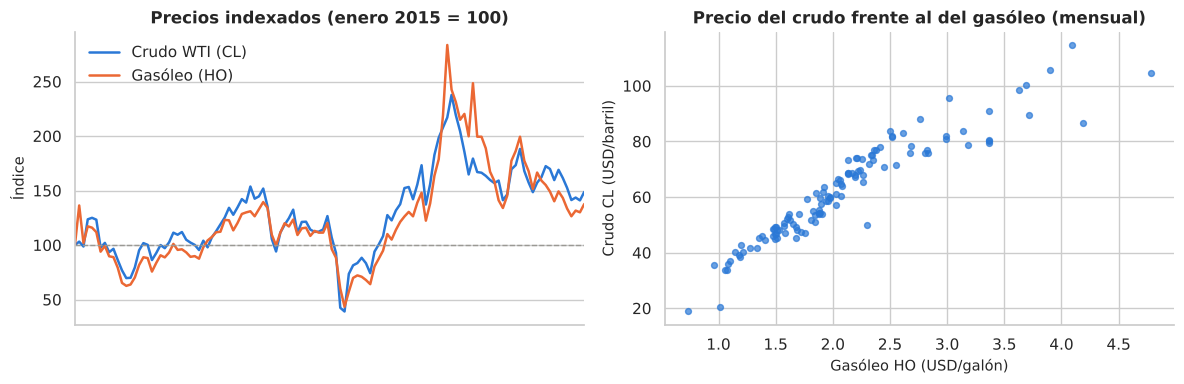

In [2]:
# Lectura rápida del archivo congelado para una primera mirada (el tratamiento formal está en el Módulo 4)
RUTA_DATOS = Path("datos_vecm.csv")
if not RUTA_DATOS.exists():
    raise FileNotFoundError("No se encuentra 'datos_vecm.csv'. Debe estar en la misma carpeta que este cuaderno.")

crudo_diario = pd.read_csv(RUTA_DATOS, parse_dates=["fecha"], index_col="fecha")
vista = crudo_diario.dropna().resample("ME").last()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
base = vista.iloc[0]
(100 * vista / base).plot(ax=axes[0], color=[COL["CL"], COL["HO"]])
axes[0].axhline(100, color=COL["ref"], lw=1, ls="--")
axes[0].set_title("Precios indexados (enero 2015 = 100)")
axes[0].set_ylabel("Índice"); axes[0].set_xlabel("")
axes[0].legend(["Crudo WTI (CL)", "Gasóleo (HO)"])
eje_fechas(axes[0], 2)

axes[1].scatter(vista.iloc[:, 1], vista.iloc[:, 0], s=18, color=COL["CL"], alpha=0.7)
axes[1].set_xlabel("Gasóleo HO (USD/galón)"); axes[1].set_ylabel("Crudo CL (USD/barril)")
axes[1].set_title("Precio del crudo frente al del gasóleo (mensual)")
plt.tight_layout(); plt.show()

**Lectura del gráfico.** Al indexar ambas series a 100 en enero de 2015 las ponemos en un mismo eje sin recurrir a
dos escalas verticales (un gráfico de doble eje permite "ajustar" visualmente cualquier par de series y suele engañar).
Las dos trayectorias suben y bajan juntas: caída de 2015-2016, colapso de 2020 y alza de 2022. El diagrama de
dispersión muestra una relación casi lineal. Pero cuidado: **dos series con tendencia casi siempre parecen
relacionadas**. El Módulo 2 muestra por qué esa impresión visual no basta.

> **Comprueba tu comprensión.** ¿Qué esperaría ver en el gráfico indexado si el margen de refinación se ampliara de
> forma permanente? ¿Seguiría habiendo cointegración?

---
## Módulo 2. Introducción intuitiva a la cointegración (datos simulados)

**Objetivo de aprendizaje:** distinguir, con ejemplos controlados, entre series que comparten una tendencia estocástica
(cointegradas) y series que solo parecen moverse juntas (correlación espuria).

### 2.1 Idea central

Una serie es **integrada de orden 1**, $I(1)$, cuando no es estacionaria en niveles pero sí en primeras diferencias.
Un paseo aleatorio $x_t = x_{t-1} + e_t$ es el ejemplo típico: sus choques son permanentes.

Dos series $I(1)$, $y_t$ y $x_t$, están **cointegradas** si existe un $b$ tal que

$$u_t = y_t - b\,x_t \quad \text{es estacionaria, } I(0).$$

Intuitivamente, ambas series "caminan" impulsadas por la **misma** tendencia estocástica, de modo que una combinación
lineal la cancela. Cuando no comparten tendencia, ninguna combinación lineal elimina la no estacionariedad.

Simulamos dos casos con $T = 300$:

- **Caso A (cointegrado):** $x_t$ es un paseo aleatorio y $y_t = 2 + 0.8\,x_t + u_t$, con $u_t = 0.6\,u_{t-1} + \eta_t$.
- **Caso B (no cointegrado):** dos paseos aleatorios **independientes**, ambos con deriva positiva.

In [3]:
rng_sim = np.random.default_rng(SEMILLA)   # semilla propia: el módulo es reproducible por sí solo
T_SIM = 300
fechas_sim = pd.RangeIndex(T_SIM, name="t")

# Caso A: cointegración
x_A = np.cumsum(rng_sim.normal(0, 1, T_SIM))
u_A = np.zeros(T_SIM)
for t in range(1, T_SIM):
    u_A[t] = 0.6 * u_A[t - 1] + rng_sim.normal(0, 1)
y_A = 2 + 0.8 * x_A + u_A

# Caso B: paseos aleatorios independientes con deriva
x_B = np.cumsum(0.30 + rng_sim.normal(0, 1, T_SIM))
y_B = np.cumsum(0.25 + rng_sim.normal(0, 1, T_SIM))

sim = pd.DataFrame({"x_A": x_A, "y_A": y_A, "x_B": x_B, "y_B": y_B}, index=fechas_sim)
print(f"Correlación caso A (cointegrado):     {sim['x_A'].corr(sim['y_A']):.3f}")
print(f"Correlación caso B (independientes):  {sim['x_B'].corr(sim['y_B']):.3f}")

Correlación caso A (cointegrado):     0.942
Correlación caso B (independientes):  0.947


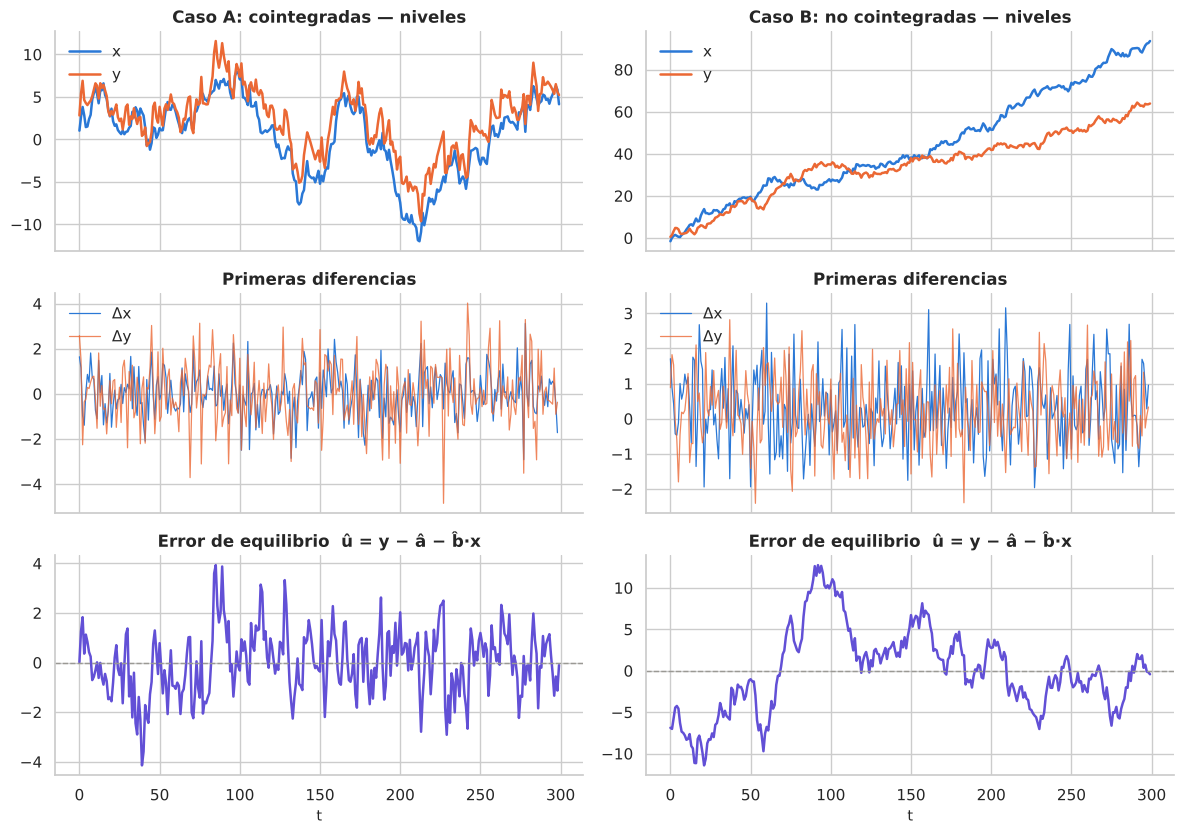

Caso A: b̂ = 0.811 | Engle-Granger estadístico = -8.47, p-valor = 0.0000
Caso B: b̂ = 0.598 | Engle-Granger estadístico = -2.15, p-valor = 0.4520


In [4]:
def ecuacion_equilibrio(y, x):
    # Regresión estática y = a + b x por MCO; devuelve (a, b, residuo)
    X = np.column_stack([np.ones_like(x), x])
    a, b = np.linalg.lstsq(X, y, rcond=None)[0]
    return a, b, y - a - b * x

aA, bA, resA = ecuacion_equilibrio(y_A, x_A)
aB, bB, resB = ecuacion_equilibrio(y_B, x_B)

fig, axes = plt.subplots(3, 2, figsize=(12, 8.5), sharex=True)
for j, (xs, ys, res, titulo) in enumerate([(x_A, y_A, resA, "Caso A: cointegradas"),
                                           (x_B, y_B, resB, "Caso B: no cointegradas")]):
    axes[0, j].plot(xs, color=COL["CL"], label="x"); axes[0, j].plot(ys, color=COL["HO"], label="y")
    axes[0, j].set_title(f"{titulo} — niveles"); axes[0, j].legend(loc="upper left")
    axes[1, j].plot(np.diff(xs), color=COL["CL"], lw=0.9, label="Δx")
    axes[1, j].plot(np.diff(ys), color=COL["HO"], lw=0.9, alpha=0.8, label="Δy")
    axes[1, j].set_title("Primeras diferencias"); axes[1, j].legend(loc="upper left")
    axes[2, j].plot(res, color=COL["ECT"])
    axes[2, j].axhline(0, color=COL["ref"], ls="--", lw=1)
    axes[2, j].set_title("Error de equilibrio  û = y − â − b̂·x")
    axes[2, j].set_xlabel("t")
plt.tight_layout(); plt.show()

# Prueba de Engle-Granger: usa valores críticos propios (no los de un ADF común),
# porque el residuo proviene de una regresión estimada.
for caso, (ys, xs, b) in {"A": (y_A, x_A, bA), "B": (y_B, x_B, bB)}.items():
    est, p, _ = coint(ys, xs, trend="c")
    print(f"Caso {caso}: b̂ = {b:.3f} | Engle-Granger estadístico = {est:.2f}, p-valor = {p:.4f}")

**Interpretación.**

- En ambos casos las series en niveles deambulan sin volver a un valor fijo y sus diferencias oscilan alrededor de cero:
  las cuatro series se comportan como $I(1)$.
- En el **caso A** el error de equilibrio cruza el cero una y otra vez: los desvíos se corrigen. La pendiente estimada
  queda cerca del valor verdadero 0.8 y la prueba de Engle-Granger rechaza la hipótesis nula de *no cointegración*.
- En el **caso B** la correlación en niveles es tan alta como en el caso A (incluso algo mayor), pero el "error de equilibrio" tiene rachas largas
  lejos de cero y la prueba no rechaza la nula: la relación es **espuria**. La alta correlación se debe únicamente a
  que ambas series tienen deriva positiva.

**Mensaje clave:** una correlación elevada entre series con tendencia no implica cointegración. Lo que importa
es si alguna combinación lineal de las series es estacionaria.

> **Error frecuente.** Aplicar un ADF ordinario al residuo de la regresión estática y usar sus valores críticos.
> Como $\hat b$ se estimó para minimizar la varianza del residuo, este parece "más estacionario" de lo que es; por eso la
> prueba de Engle-Granger (`coint`) usa valores críticos más exigentes.

> **Comprueba tu comprensión.** Cambie el 0.6 del caso A por 0.98 y vuelva a ejecutar. ¿Qué le pasa al error de
> equilibrio y al p-valor? ¿Las series siguen estando cointegradas en sentido teórico?

---
## Módulo 3. Del VAR al VECM

**Objetivo de aprendizaje:** entender por qué un VECM es una forma reorganizada de un VAR en niveles y qué significan
$\Pi$, $\alpha$, $\beta$ y $\Gamma$.

### 3.1 Punto de partida: un VAR

Un VAR($p$) con $k$ variables escribe cada variable como función de sus rezagos y de los rezagos de las demás:

$$\mathbf{y}_t = \mathbf{c} + \mathbf{A}_1\mathbf{y}_{t-1} + \cdots + \mathbf{A}_p\mathbf{y}_{t-p} + \boldsymbol{\varepsilon}_t,
\qquad \boldsymbol{\varepsilon}_t \sim (\mathbf{0}, \boldsymbol{\Sigma}),$$

donde $\mathbf{y}_t$ es $k\times 1$, cada $\mathbf{A}_i$ es $k\times k$ y $\boldsymbol\Sigma$ es la matriz de covarianzas de los errores.

**Limitaciones con series $I(1)$:**

- *VAR en niveles:* puede estimarse, pero la inferencia estándar (pruebas $t$ y $F$) no es válida en general, y
  no separa explícitamente el corto del largo plazo.
- *VAR en diferencias:* las diferencias son estacionarias, pero al diferenciar **se elimina toda la información sobre
  el nivel**. Si las series están cointegradas, ese VAR omite una variable relevante: la distancia al equilibrio.

### 3.2 Caso bivariado con un rezago

Tomemos $k=2$, $p=1$: $\mathbf{y}_t = \mathbf{c} + \mathbf{A}_1 \mathbf{y}_{t-1} + \boldsymbol\varepsilon_t$.
Restando $\mathbf{y}_{t-1}$ a ambos lados:

$$\Delta\mathbf{y}_t = \mathbf{c} + (\mathbf{A}_1 - \mathbf{I})\,\mathbf{y}_{t-1} + \boldsymbol\varepsilon_t
= \mathbf{c} + \boldsymbol\Pi\,\mathbf{y}_{t-1} + \boldsymbol\varepsilon_t .$$

Si las series están cointegradas con una relación ($r=1$), la matriz $\boldsymbol\Pi$ tiene rango 1 y se factoriza como
$\boldsymbol\Pi = \boldsymbol\alpha\boldsymbol\beta'$, con $\boldsymbol\alpha$ y $\boldsymbol\beta$ de dimensión $2\times 1$:

$$\begin{pmatrix}\Delta y_{1t}\\ \Delta y_{2t}\end{pmatrix}
= \begin{pmatrix}c_1\\ c_2\end{pmatrix}
+ \begin{pmatrix}\alpha_1\\ \alpha_2\end{pmatrix}
\underbrace{\big(\beta_1 y_{1,t-1} + \beta_2 y_{2,t-1}\big)}_{\text{desequilibrio en } t-1\ (ECT_{t-1})}
+ \begin{pmatrix}\varepsilon_{1t}\\ \varepsilon_{2t}\end{pmatrix}.$$

Cada variable cambia hoy en respuesta a **qué tan lejos estuvo el sistema del equilibrio ayer**.

### 3.3 Forma general

Para un VAR($p$), la reorganización da

$$\Delta\mathbf{y}_t = \mathbf{c} + \boldsymbol\alpha\boldsymbol\beta'\mathbf{y}_{t-1}
+ \sum_{i=1}^{p-1}\boldsymbol\Gamma_i\,\Delta\mathbf{y}_{t-i} + \boldsymbol\varepsilon_t,
\qquad \boldsymbol\Pi = -\Big(\mathbf{I} - \sum_{i=1}^{p}\mathbf{A}_i\Big),\quad
\boldsymbol\Gamma_i = -\sum_{j=i+1}^{p}\mathbf{A}_j .$$

| Símbolo | Dimensión | Significado |
|---|---|---|
| $\boldsymbol\beta$ | $k\times r$ | Vectores de cointegración: definen las combinaciones $\boldsymbol\beta'\mathbf{y}_t$ estacionarias (largo plazo) |
| $\boldsymbol\alpha$ | $k\times r$ | Coeficientes de ajuste (*loadings*): cómo responde cada ecuación al desequilibrio |
| $\boldsymbol\Gamma_i$ | $k\times k$ | Dinámica de corto plazo: efecto de los cambios pasados sobre los cambios actuales |
| $r$ | escalar | Rango de cointegración = número de relaciones de equilibrio independientes |

**Relación con los rezagos:** un VECM con `k_ar_diff` $=p-1$ rezagos en diferencias equivale a un VAR($p$) en niveles.
Un VECM con `k_ar_diff = 0` (ningún $\Gamma_i$) es perfectamente válido: corresponde a un VAR(1) en niveles.

| Rango de $\boldsymbol\Pi$ | Implicación | Modelo natural |
|---|---|---|
| $r = 0$ | No hay cointegración; $\boldsymbol\Pi = \mathbf 0$ | VAR en primeras diferencias |
| $0 < r < k$ | $r$ relaciones de equilibrio | **VECM** |
| $r = k$ | $\boldsymbol\Pi$ de rango completo: el sistema es estacionario | VAR en niveles |

### 3.4 Dos aclaraciones sobre $\alpha$ y $\beta$

1. **La factorización no es única.** Para cualquier $c\neq 0$, $\boldsymbol\alpha\boldsymbol\beta' = (\boldsymbol\alpha c)(\boldsymbol\beta/c)'$.
   Por eso se **normaliza** $\beta$ (por ejemplo, primer elemento igual a 1). La normalización es una convención
   matemática, no una afirmación causal: normalizar sobre el crudo no significa que el gasóleo "cause" al crudo.
2. **El signo de $\alpha$ depende de la normalización.** Con $ECT = y_1 - b\,y_2$, la variable 1 corrige si
   $\alpha_1<0$, pero la variable 2 corrige si $\alpha_2>0$ (cuando $ECT>0$, $y_1$ está "alto" relativo a $y_2$, y que
   $y_2$ suba también cierra la brecha). **Un $\alpha$ positivo no es, por sí solo, una señal de error.**

### 3.5 Ejemplo numérico: cuánto se corrige realmente

Suponga $\boldsymbol\beta = (1,\,-1)'$, $\boldsymbol\alpha = (-0.25,\ 0.10)'$, sin rezagos en diferencias ni choques,
y un desequilibrio inicial $ECT_{t-1} = 0.10$:

- $\Delta y_{1t} = -0.25\times 0.10 = -0.025$ (la variable 1 baja)
- $\Delta y_{2t} = \ \ 0.10\times 0.10 = \ \ 0.010$ (la variable 2 sube)
- Nuevo desequilibrio: $ECT_t = ECT_{t-1} + \Delta y_{1t} - \Delta y_{2t} = 0.10 - 0.025 - 0.010 = 0.065$.

Se corrigió el 35 % de la brecha, no el 25 % que sugeriría mirar solo $\alpha_1$. En general, el desequilibrio evoluciona
según $ECT_t = (1 + \boldsymbol\beta'\boldsymbol\alpha)\,ECT_{t-1} + \dots$, y aquí
$\boldsymbol\beta'\boldsymbol\alpha = -0.25 - 0.10 = -0.35$. **Un $\alpha$ individual no es el porcentaje total de
corrección por período.** Con más rezagos ($\Gamma\neq 0$) la dinámica del desequilibrio depende también de $\Gamma$.

Comprobemos que un VECM estimado recupera estos parámetros cuando los datos se generan con ellos.

In [5]:
# Simulación de un VECM verdadero: Δy_t = α β' y_{t-1} + ε_t
alpha_v = np.array([[-0.25], [0.10]])
beta_v = np.array([[1.0], [-1.0]])
T_V = 1000
rng_v = np.random.default_rng(SEMILLA + 1)
Y = np.zeros((T_V, 2))
eps = rng_v.multivariate_normal([0, 0], [[1.0, 0.5], [0.5, 1.0]], size=T_V)
for t in range(1, T_V):
    Y[t] = Y[t - 1] + (alpha_v @ beta_v.T @ Y[t - 1]) + eps[t]
Y = pd.DataFrame(Y, columns=["y1", "y2"])

res_sim = VECM(Y, k_ar_diff=0, coint_rank=1, deterministic="n").fit()
comparacion = pd.DataFrame({
    "verdadero": [beta_v[1, 0], alpha_v[0, 0], alpha_v[1, 0], (beta_v.T @ alpha_v).item()],
    "estimado": [res_sim.beta[1, 0], res_sim.alpha[0, 0], res_sim.alpha[1, 0], (res_sim.beta.T @ res_sim.alpha).item()],
    "error est.": [res_sim.stderr_beta[1, 0], res_sim.stderr_alpha[0, 0], res_sim.stderr_alpha[1, 0], np.nan],
}, index=["β₂ (β₁ = 1)", "α₁", "α₂", "β'α"])
display(comparacion.round(3))

# Trayectoria determinista del ejemplo numérico (sin choques)
ect = [0.10]
for _ in range(10):
    ect.append((1 + (beta_v.T @ alpha_v).item()) * ect[-1])
print("Desequilibrio en t = 0..5:", np.round(ect[:6], 4))

,verdadero,estimado,error est.
β₂ (β₁ = 1),-1.00,-0.995,0.014
α₁,-0.25,-0.196,0.022
α₂,0.10,0.084,0.022
β'α,-0.35,-0.280,NaN


Desequilibrio en t = 0..5: [0.1    0.065  0.0422 0.0275 0.0179 0.0116]


**Interpretación.** Con 1 000 observaciones simuladas, $\hat\beta_2$ queda muy cerca de −1 y con un error estándar
diminuto, mientras que los $\hat\alpha$ tienen los signos correctos pero pueden alejarse de los valores verdaderos
hasta dos o tres veces su error estándar (aquí, $\hat\alpha_1$). No es un fallo del método: **el vector de cointegración se estima con mucha más precisión
que las velocidades de ajuste** (el estimador de $\beta$ es *superconsistente*, converge a ritmo $T$ y no $\sqrt T$).
Recuerde este resultado: en los datos reales, $\alpha$ será la parte frágil del análisis. La secuencia determinista
muestra que el desequilibrio se reduce un 35 % por período (factor $0.65$), tal como se calculó a mano.

> **Comprueba tu comprensión.** Si $\boldsymbol\alpha = (0,\ 0.10)'$, ¿qué variable corrige el desequilibrio? ¿Cómo se
> llama la propiedad de la variable 1 en ese caso? (Pista: exogeneidad débil.)

---
## Módulo 4. Exploración y preparación de los datos reales

**Objetivo de aprendizaje:** conocer la procedencia, unidades y limitaciones de los datos y justificar cada
transformación.

### 4.1 Fuente y contenido del archivo congelado

| Columna | Instrumento | Unidad |
|---|---|---|
| `CL_F_cierre_usd_barril` | Futuro continuo de crudo WTI, NYMEX (`CL=F`) | USD por barril |
| `HO_F_cierre_usd_galon` | Futuro continuo de gasóleo de calefacción (NY Harbor ULSD), NYMEX (`HO=F`) | USD por galón |

- **Procedencia:** Yahoo Finance, *endpoint* de gráficos (`v8/finance/chart`), intervalo diario, cierre sin ajustar,
  del 2 de enero de 2015 al 31 de diciembre de 2024. Descargado el 31 de octubre de 2026 y guardado sin modificar
  (incluidos los días sin dato y el precio negativo de abril de 2020). Las fechas están en la zona horaria de la bolsa (Nueva York).
- **Contrato continuo:** `CL=F` y `HO=F` empalman el contrato más próximo a vencer. En cada vencimiento puede
  aparecer un salto que no es un cambio de precio "real" (*efecto de empalme*). Lo tendremos presente al revisar
  observaciones extremas.
- **Diferencia con el cuaderno original:** el original descargaba los datos en cada ejecución, de modo que los resultados
  podían cambiar con las revisiones del proveedor. Aquí el caso base es siempre el mismo archivo.

La descarga directa queda como opción (`DESCARGAR = False` por defecto). Atención a un detalle que causó un error en
`15_vecm_preliminar.ipynb`: `yfinance` devuelve las columnas **en orden alfabético** (`CL=F`, `HO=F`), por lo que
renombrarlas como `['HeatingOil', 'CrudeOil']` intercambia las etiquetas. La función de abajo renombra por nombre, no por posición.

In [6]:
DESCARGAR = False   # True solo si quiere actualizar los datos desde internet (requiere yfinance)

def descargar_yfinance(inicio="2015-01-01", fin="2025-01-01"):
    # Descarga opcional. Renombra por símbolo (no por posición) para no intercambiar etiquetas.
    import yfinance as yf
    datos = yf.download(["CL=F", "HO=F"], start=inicio, end=fin, auto_adjust=False, progress=False)["Close"]
    datos = datos.rename(columns={"CL=F": "CL_F_cierre_usd_barril", "HO=F": "HO_F_cierre_usd_galon"})
    datos.index.name = "fecha"
    return datos[["CL_F_cierre_usd_barril", "HO_F_cierre_usd_galon"]]

if DESCARGAR:
    try:
        diario = descargar_yfinance()
        print("Datos descargados. Los resultados pueden diferir de los del texto.")
    except Exception as err:
        print(f"Descarga fallida ({err}); se usa el archivo local.")
        diario = pd.read_csv(RUTA_DATOS, parse_dates=["fecha"], index_col="fecha")
else:
    diario = pd.read_csv(RUTA_DATOS, parse_dates=["fecha"], index_col="fecha")

diario = diario.sort_index()
assert diario.index.is_unique, "Hay fechas duplicadas"
print(f"Observaciones diarias : {len(diario)}")
print(f"Rango de fechas       : {diario.index.min().date()} → {diario.index.max().date()}")
print("\nValores faltantes por columna:")
print(diario.isna().sum().to_string())
print("\nPrecios no positivos:")
display(diario[(diario <= 0).any(axis=1)])
display(diario.describe().T.round(3))

Observaciones diarias : 2517
Rango de fechas       : 2015-01-02 → 2024-12-31

Valores faltantes por columna:
CL_F_cierre_usd_barril    3
HO_F_cierre_usd_galon     2

Precios no positivos:


,CL_F_cierre_usd_barril,HO_F_cierre_usd_galon
fecha,,
2020-04-20,-37.63,0.8878


,count,mean,std,min,25%,50%,75%,max
CL_F_cierre_usd_barril,2514.0,62.001,18.116,-37.63,48.52,59.950,74.025,123.700
HO_F_cierre_usd_galon,2515.0,2.084,0.714,0.61,1.58,1.958,2.413,5.135


**Lectura de la inspección.**

- Hay unos pocos días sin dato, ligados a feriados en que uno de los contratos no cotizó. Como trabajaremos con el
  último cierre de cada mes, basta con eliminar esos días: no se imputa nada.
- El 20 de abril de 2020 el contrato de crudo cerró en **−37.63 USD/barril**. No es un error de captura: fue el
  vencimiento del contrato de mayo de 2020, en plena caída de demanda por la pandemia y con el almacenamiento saturado.
  Un precio negativo impide tomar logaritmos; por eso el análisis diario en logaritmos no es viable, pero el cierre
  de fin de mes de abril de 2020 sí es positivo. Lo verificamos explícitamente abajo en lugar de suponerlo.

### 4.2 Frecuencia y transformación

1. **Frecuencia mensual (último cierre del mes).** La pregunta es de largo plazo; el dato diario añade ruido de
   microestructura y complica la dinámica de rezagos. El costo es que quedan $T=120$ observaciones, una muestra
   moderada para un VECM: las conclusiones deben formularse con cautela.
2. **Logaritmos.** Con logaritmos, las diferencias son tasas de variación aproximadas, la relación de equilibrio se lee
   como elasticidad y se reduce la dependencia de la variabilidad respecto al nivel del precio.
3. **Unidades.** Un barril son 42 galones. No convertimos unidades porque en logaritmos un cambio de unidad solo
   desplaza la constante de la relación de equilibrio, no la pendiente.

In [7]:
mensual = diario.dropna().resample("ME").last()
mensual.index.freq = "ME"          # frecuencia explícita: statsmodels la usa para fechar pronósticos

if (mensual <= 0).any().any():
    raise ValueError("Hay precios mensuales no positivos: no se puede tomar logaritmo.")

datos = np.log(mensual).rename(columns={"CL_F_cierre_usd_barril": "ln_CL", "HO_F_cierre_usd_galon": "ln_HO"})
dif = datos.diff().dropna()

assert datos.isna().sum().sum() == 0
print(f"Observaciones mensuales: T = {len(datos)}  ({datos.index[0]:%Y-%m} → {datos.index[-1]:%Y-%m})")
print(f"Cierre de abril 2020 (crudo): {mensual.loc['2020-04', 'CL_F_cierre_usd_barril'].iloc[0]:.2f} USD/barril")
display(pd.concat([datos.describe().T, dif.describe().T.rename(index=lambda s: "Δ" + s)]).round(4))

Observaciones mensuales: T = 120  (2015-01 → 2024-12)
Cierre de abril 2020 (crudo): 18.84 USD/barril


,count,mean,std,min,25%,50%,75%,max
ln_CL,120.0,4.0853,0.3050,2.9360,3.8810,4.0980,4.3185,4.7421
ln_HO,120.0,0.6818,0.3416,-0.3121,0.4583,0.6752,0.8618,1.5648
Δln_CL,119.0,0.0033,0.1300,-0.7819,-0.0608,0.0150,0.0674,0.6333
Δln_HO,119.0,0.0027,0.1158,-0.3872,-0.0548,0.0043,0.0709,0.3099


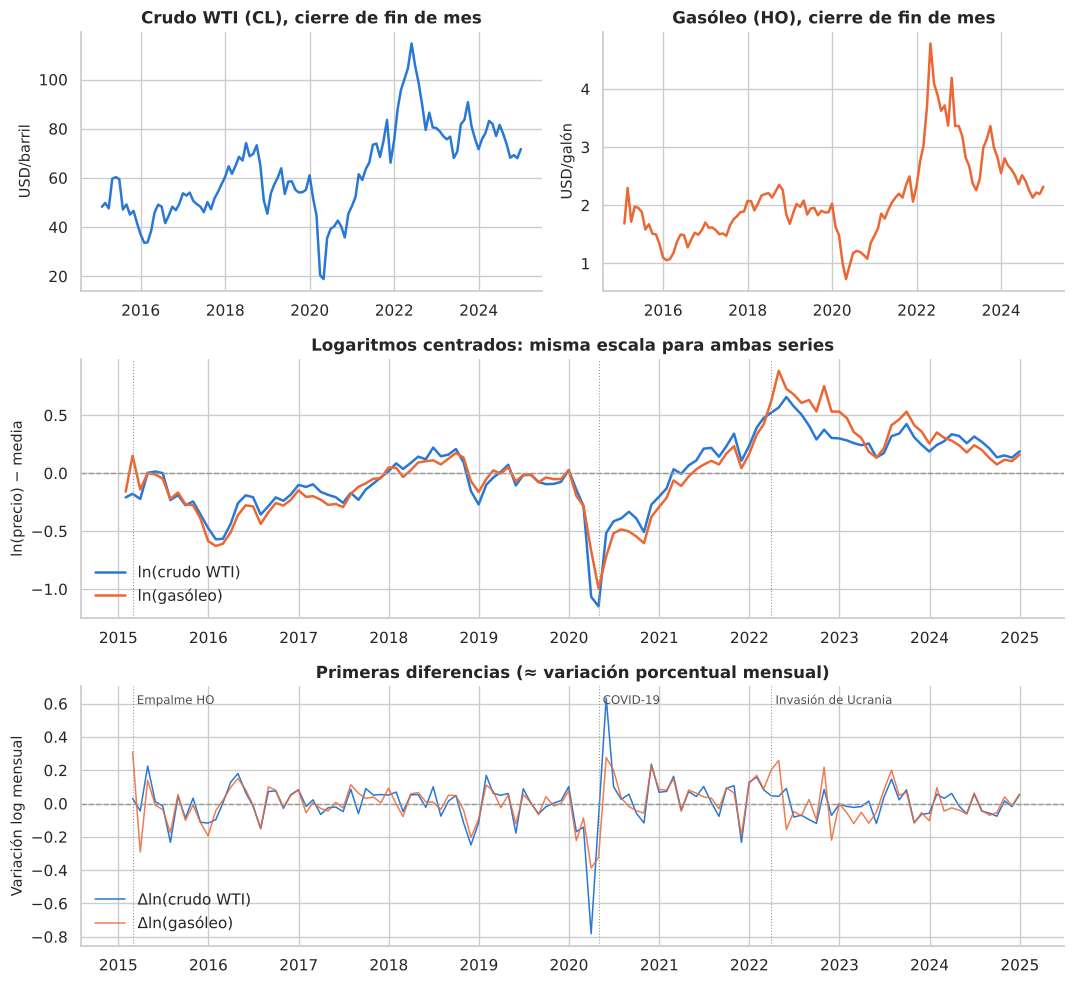

Mayores variaciones absolutas mensuales:


,,|Δln|
fecha,,
2020-03-31,ln_CL,0.782
2020-05-31,ln_CL,0.633
2020-03-31,ln_HO,0.387
2020-04-30,ln_HO,0.324
2015-02-28,ln_HO,0.310


In [8]:
fig = plt.figure(figsize=(11, 10))
gs = fig.add_gridspec(3, 2)
ax_cl, ax_ho = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])
axes = [None, fig.add_subplot(gs[1, :]), None]
axes[2] = fig.add_subplot(gs[2, :], sharex=axes[1])
ax_cl.plot(mensual.index, mensual.iloc[:, 0], color=COL["CL"]); ax_cl.set_ylabel("USD/barril")
ax_cl.set_title("Crudo WTI (CL), cierre de fin de mes")
ax_ho.plot(mensual.index, mensual.iloc[:, 1], color=COL["HO"]); ax_ho.set_ylabel("USD/galón")
ax_ho.set_title("Gasóleo (HO), cierre de fin de mes")
for ax in (ax_cl, ax_ho):
    eje_fechas(ax, 2)

axes[1].plot(datos.index, datos["ln_CL"] - datos["ln_CL"].mean(), color=COL["CL"], label=ETIQ["ln_CL"])
axes[1].plot(datos.index, datos["ln_HO"] - datos["ln_HO"].mean(), color=COL["HO"], label=ETIQ["ln_HO"])
axes[1].axhline(0, color=COL["ref"], ls="--", lw=1)
axes[1].set_ylabel("ln(precio) − media")
axes[1].set_title("Logaritmos centrados: misma escala para ambas series")
axes[1].legend(loc="lower left")

axes[2].plot(dif.index, dif["ln_CL"], color=COL["CL"], lw=1.1, label="Δ" + ETIQ["ln_CL"])
axes[2].plot(dif.index, dif["ln_HO"], color=COL["HO"], lw=1.1, alpha=0.85, label="Δ" + ETIQ["ln_HO"])
axes[2].axhline(0, color=COL["ref"], ls="--", lw=1)
axes[2].set_ylabel("Variación log mensual")
axes[2].set_title("Primeras diferencias (≈ variación porcentual mensual)")
axes[2].legend(loc="lower left")
for fecha, txt in [("2020-04-30", "COVID-19"), ("2022-03-31", "Invasión de Ucrania"), ("2015-02-28", "Empalme HO")]:
    for ax in axes[1:]:
        ax.axvline(pd.Timestamp(fecha), color=COL["ref"], lw=0.8, ls=":")
    axes[2].annotate(txt, (pd.Timestamp(fecha), axes[2].get_ylim()[1] * 0.85), fontsize=8.5, color="#52514e",
                     ha="left", xytext=(3, 0), textcoords="offset points")
eje_fechas(axes[2])
plt.tight_layout(); plt.show()

print("Mayores variaciones absolutas mensuales:")
display(dif.abs().stack().nlargest(5).rename("|Δln|").round(3).to_frame())

**Interpretación de los gráficos.**

- **Niveles y logaritmos:** ninguna serie gira alrededor de una media fija; los logaritmos centrados se superponen
  durante casi toda la muestra, lo que sugiere —sin probarlo— una tendencia estocástica común.
- **Diferencias:** oscilan alrededor de cero, con episodios de alta volatilidad. El mayor movimiento mensual del
  crudo ocurre en marzo de 2020 (≈ −0.78 en logaritmos, una caída cercana al 54 %), seguido del rebote de mayo de 2020.
- **Febrero-marzo de 2015 en el gasóleo:** una subida de ≈ 31 % seguida de una caída equivalente al mes siguiente.
  Coincide con el vencimiento del contrato de marzo de 2015 en un invierno muy frío; es plausible que parte del salto sea
  efecto del empalme del contrato continuo. No lo eliminamos (no tenemos un dato alternativo verificable), pero lo
  señalamos como observación influyente.
- **Posibles quiebres estructurales:** 2020 (pandemia) y 2022 (choque de oferta tras la invasión de Ucrania, con un
  margen de refinación de destilados históricamente alto). El Módulo 8 evalúa si la relación estimada es estable.

> **Errores frecuentes.** (1) Tomar logaritmos sin verificar que los precios sean positivos. (2) Usar un gráfico de doble
> eje para "mostrar" que dos series se mueven juntas. (3) Mezclar frecuencias o cerrar meses con días distintos para cada serie.

> **Comprueba tu comprensión.** ¿Qué cambiaría si en vez del último cierre usara el promedio mensual? Piense en el
> efecto sobre la autocorrelación de las diferencias.

---
## Módulo 5. Estacionariedad e integración

**Objetivo de aprendizaje:** combinar ADF, KPSS, gráficos y argumentos económicos para decidir —con la incertidumbre
adecuada— si las series son $I(1)$.

### 5.1 ¿Por qué hace falta este paso?

La cointegración solo tiene sentido entre series $I(1)$ (o, en general, del mismo orden de integración). Si las series
fueran estacionarias, un VAR en niveles bastaría; si una fuera $I(2)$, el VECM estándar no sería adecuado.

### 5.2 Dos pruebas con hipótesis nulas opuestas

| Prueba | $H_0$ | $H_1$ | Rechazar $H_0$ sugiere |
|---|---|---|---|
| **ADF** (Dickey-Fuller aumentada) | Raíz unitaria | Estacionaria (alrededor de la parte determinista) | Estacionariedad |
| **KPSS** | Estacionaria (alrededor de la parte determinista) | Raíz unitaria | No estacionariedad |

La regresión ADF es $\Delta y_t = a + \delta t + \rho\,y_{t-1} + \sum_{j=1}^{m}\phi_j\Delta y_{t-j} + e_t$, con
$H_0:\rho = 0$. La parte determinista (solo constante `'c'`, o constante y tendencia `'ct'`) **cambia la pregunta**:
con `'ct'` la alternativa es "estacionaria alrededor de una tendencia lineal".

**Cómo leerlas juntas:**

| ADF | KPSS | Lectura |
|---|---|---|
| No rechaza | Rechaza | Evidencia coherente de raíz unitaria |
| Rechaza | No rechaza | Evidencia coherente de estacionariedad |
| No rechaza | No rechaza | Datos poco informativos (baja potencia): decidir con gráficos y teoría |
| Rechaza | Rechaza | Señales contradictorias: posible quiebre, memoria larga o mala especificación determinista |

**No rechazar una nula no la demuestra.** Con 120 observaciones ambas pruebas tienen potencia limitada.

**¿Constante o tendencia?** Para los logaritmos de precios del petróleo no hay un argumento económico para una tendencia
determinista lineal en 2015-2024 (no hay razón para un crecimiento sistemático a tasa fija). La especificación principal
es por tanto **solo constante**; la de tendencia se reporta como análisis de sensibilidad. Para las diferencias se usa
constante.

In [9]:
def prueba_adf(serie, regresion):
    est, p, rez, _, vc, _ = adfuller(serie.dropna(), regression=regresion, autolag="AIC")
    return est, p, rez, vc["5%"]

def prueba_kpss(serie, regresion):
    est, p, rez, vc = kpss(serie.dropna(), regression=regresion, nlags="auto")
    # statsmodels acota el p-valor de KPSS a [0.01, 0.10]; lo dejamos explícito en la tabla
    p_txt = "< 0.01" if p <= 0.01 else ("> 0.10" if p >= 0.10 else f"{p:.3f}")
    return est, p, p_txt, vc["5%"]

def tabla_raiz_unitaria(df, sufijo="", regresiones=("c", "ct"), alfa=0.05):
    filas = []
    for col in df.columns:
        for reg in regresiones:
            a_est, a_p, a_rez, a_vc = prueba_adf(df[col], reg)
            k_est, k_p, k_txt, k_vc = prueba_kpss(df[col], reg)
            adf_rech, kpss_rech = a_p < alfa, k_p < alfa
            lectura = {(False, True): "Raíz unitaria (coherente)",
                       (True, False): "Estacionaria (coherente)",
                       (False, False): "No concluyente",
                       (True, True): "Contradictorio"}[(adf_rech, kpss_rech)]
            filas.append({"Serie": sufijo + ETIQ.get(col, col),
                          "Determinista": {"c": "constante", "ct": "const. + tendencia"}[reg],
                          "ADF estad.": a_est, "ADF VC 5%": a_vc, "ADF p": a_p, "ADF rezagos": a_rez,
                          "ADF: rechaza H0 (raíz unit.)": "sí" if adf_rech else "no",
                          "KPSS estad.": k_est, "KPSS VC 5%": k_vc, "KPSS p": k_txt,
                          "KPSS: rechaza H0 (estac.)": "sí" if kpss_rech else "no",
                          "Lectura conjunta": lectura})
    return pd.DataFrame(filas)

tab_niv = tabla_raiz_unitaria(datos)
tab_dif = tabla_raiz_unitaria(dif, sufijo="Δ", regresiones=("c",))
tabla_ur = pd.concat([tab_niv, tab_dif], ignore_index=True)
display(tabla_ur.round({"ADF estad.": 3, "ADF VC 5%": 3, "ADF p": 4, "KPSS estad.": 3, "KPSS VC 5%": 3}))

,Serie,Determinista,ADF estad.,ADF VC 5%,ADF p,ADF rezagos,ADF: rechaza H0 (raíz unit.),KPSS estad.,KPSS VC 5%,KPSS p,KPSS: rechaza H0 (estac.),Lectura conjunta
0,ln(crudo WTI),constante,-1.675,-2.887,0.4440,4,no,0.864,0.463,< 0.01,sí,Raíz unitaria (coherente)
1,ln(crudo WTI),const. + tendencia,-2.895,-3.449,0.1637,2,no,0.110,0.146,> 0.10,no,No concluyente
2,ln(gasóleo),constante,-1.922,-2.886,0.3219,1,no,0.807,0.463,< 0.01,sí,Raíz unitaria (coherente)
3,ln(gasóleo),const. + tendencia,-2.796,-3.448,0.1983,1,no,0.104,0.146,> 0.10,no,No concluyente
4,Δln(crudo WTI),constante,-7.133,-2.887,0.0000,3,sí,0.040,0.463,> 0.10,no,Estacionaria (coherente)
5,Δln(gasóleo),constante,-10.473,-2.886,0.0000,0,sí,0.052,0.463,> 0.10,no,Estacionaria (coherente)


**Interpretación (valores de la tabla anterior).**

1. **Niveles con constante (especificación principal):** ADF no rechaza la raíz unitaria en ninguna serie
   (p ≈ 0.44 para el crudo y ≈ 0.32 para el gasóleo) y KPSS rechaza la estacionariedad al 1 %. Ambas pruebas
   apuntan en la misma dirección: **evidencia coherente de no estacionariedad en niveles**.
2. **Niveles con constante y tendencia:** ADF sigue sin rechazar (p ≈ 0.16 y ≈ 0.20), pero KPSS ya **no** rechaza
   la estacionariedad alrededor de una tendencia. Es el caso "no concluyente": con 120 datos no podemos distinguir con
   claridad entre una raíz unitaria y un proceso persistente alrededor de una tendencia lineal. Como no hay razón
   económica para esa tendencia, no le damos más peso, pero dejamos constancia de la ambigüedad.
3. **Primeras diferencias:** ADF rechaza con fuerza la raíz unitaria (p < 0.001) y KPSS no rechaza la
   estacionariedad. Las diferencias se comportan como $I(0)$, lo que descarta un orden $I(2)$.

**Decisión metodológica.** Tratamos ambas series como $I(1)$. Es una conclusión **razonable, no demostrada**: se apoya
en la especificación con constante, en los gráficos del Módulo 4 y en la naturaleza de los precios de activos; la
especificación con tendencia deja abierta cierta duda.

> **Corrección respecto al cuaderno original.** El original usaba únicamente `'ct'`, obtenía "ADF: no estacionaria" y
> "KPSS: estacionaria" en niveles, y aun así concluía "ambas series son I(1)" basándose solo en el ADF de las
> diferencias. Esa conclusión pasaba por alto la contradicción entre las dos pruebas.

> **Error frecuente.** Leer "KPSS p-valor = 0.10" como un p-valor exacto. `statsmodels` interpola en una tabla corta y
> lo trunca: significa "0.10 o más".

> **Comprueba tu comprensión.** Si ADF y KPSS rechazaran ambas sus hipótesis nulas en niveles, ¿qué explicaciones
> considerarías antes de seguir con el VECM?

---
## Módulo 6. Selección de rezagos y prueba de cointegración de Johansen

**Objetivo de aprendizaje:** elegir de forma justificada el número de rezagos y la especificación determinista, y
decidir el rango de cointegración reconociendo cuándo la evidencia es débil.

### 6.1 Rezagos: qué son y por qué importan

Los rezagos en diferencias ($\Gamma_1,\dots,\Gamma_{p-1}$) capturan la dinámica de corto plazo. Pocos rezagos dejan
autocorrelación en los residuos (la prueba de Johansen pierde validez); demasiados consumen grados de libertad
(con $T=120$, cada rezago adicional agrega $k^2 = 4$ parámetros) y reducen la potencia.

Los criterios de información equilibran ajuste y complejidad, $\text{IC}(m) = \ln|\hat{\boldsymbol\Sigma}_m| + \frac{c_T}{T}\,N_m$:

| Criterio | Penalización $c_T$ | Tendencia |
|---|---|---|
| AIC | $2$ | Elige modelos más grandes; orientado a pronóstico |
| BIC (SC) | $\ln T$ | El más parsimonioso; consistente si el modelo verdadero está entre los candidatos |
| HQIC | $2\ln\ln T$ | Intermedio |

**Sobre `select_order`:** en `statsmodels`, `vecm.select_order` ya devuelve el número de rezagos **en diferencias**
(`k_ar_diff`) del VECM; no hay que restarle 1. El cuaderno original restaba una unidad y luego imponía un mínimo de 1
(`max(1, ...)`), dos errores que se compensaban por casualidad.

In [10]:
MAX_REZAGOS = 12
sel = select_order(datos, maxlags=MAX_REZAGOS, deterministic="co")
print(sel.summary())
rez = {"AIC": sel.aic, "BIC": sel.bic, "HQIC": sel.hqic, "FPE": sel.fpe}
print("\nk_ar_diff sugerido (rezagos en diferencias del VECM):", rez)
print("Equivale a un VAR en niveles de orden p = k_ar_diff + 1:", {k: v + 1 for k, v in rez.items()})

 VECM Order Selection (* highlights the minimums) 
       AIC         BIC         FPE         HQIC   
--------------------------------------------------
0       -9.648     -9.448*   6.456e-05     -9.567*
1       -9.646      -9.346   6.470e-05      -9.524
2      -9.664*      -9.264  6.358e-05*      -9.502
3       -9.600      -9.101   6.779e-05      -9.398
4       -9.620      -9.021   6.650e-05      -9.377
5       -9.555      -8.856   7.104e-05      -9.272
6       -9.514      -8.715   7.415e-05      -9.190
7       -9.456      -8.557   7.872e-05      -9.092
8       -9.396      -8.397   8.382e-05      -8.991
9       -9.331      -8.232   8.972e-05      -8.885
10      -9.284      -8.085   9.433e-05      -8.798
11      -9.232      -7.933   9.985e-05      -8.705
12      -9.199      -7.800   0.0001037      -8.632
--------------------------------------------------

k_ar_diff sugerido (rezagos en diferencias del VECM): {'AIC': np.int64(2), 'BIC': np.int64(0), 'HQIC': np.int64(0), 'FPE': np.int64(

**Interpretación.** BIC y HQIC eligen `k_ar_diff = 0` (un VAR(1) en niveles), mientras AIC y FPE eligen
`k_ar_diff = 2`. La superficie de AIC es muy plana entre 0 y 4 rezagos: las diferencias de criterio son pequeñas.

**Decisión.** Adoptamos **BIC → `k_ar_diff = 0`** como especificación principal porque (i) la muestra es corta,
(ii) el objetivo central es inferencia sobre la relación de largo plazo, donde la parsimonia ayuda, y (iii) en el
Módulo 8 verificaremos que con 0 rezagos los residuos no muestran autocorrelación (condición necesaria para aceptar la
elección). La alternativa de AIC (`k_ar_diff = 2`) se mantiene en todos los análisis de sensibilidad y compite en la
validación de pronósticos del Módulo 10.

### 6.2 La prueba de Johansen

Johansen estima $\boldsymbol\Pi$ por máxima verosimilitud y calcula sus **autovalores** $\hat\lambda_1>\dots>\hat\lambda_k$
(correlaciones canónicas al cuadrado entre $\Delta\mathbf y_t$ y $\mathbf y_{t-1}$, una vez filtrada la dinámica de
corto plazo). Autovalores grandes indican combinaciones de los niveles que ayudan a predecir los cambios: relaciones de cointegración.

- **Traza:** $\lambda_{traza}(r_0) = -T\sum_{i=r_0+1}^{k}\ln(1-\hat\lambda_i)$, contrasta $H_0: r\le r_0$ frente a $H_1: r > r_0$.
- **Máximo autovalor:** $\lambda_{max}(r_0) = -T\ln(1-\hat\lambda_{r_0+1})$, contrasta $H_0: r = r_0$ frente a $H_1: r = r_0+1$.

Se procede **secuencialmente** desde $r_0=0$ y se elige el primer $r_0$ que no se rechaza. Los estadísticos no tienen
distribución $\chi^2$: sus valores críticos (Osterwald-Lenum, 1992) dependen de $k-r_0$ y de los términos deterministas.

### 6.3 Compatibilidad de los términos deterministas

Este es un punto delicado de la API: `coint_johansen` usa `det_order` y `VECM` usa `deterministic`, y **no son códigos
intercambiables**.

| `coint_johansen(det_order=...)` | Qué hace | Equivalente en `VECM(deterministic=...)` |
|---|---|---|
| `-1` | Sin términos deterministas | `"n"` |
| `0` | Constante sin restringir (los niveles pueden tener deriva) | `"co"` |
| `1` | Constante y tendencia lineal sin restringir | `"colo"` |
| — | Constante restringida a la relación de cointegración | `"ci"` (sin equivalente directo en `coint_johansen`) |

Usamos `det_order = 0` en la prueba y `deterministic = "co"` en el VECM, que son la **misma** especificación.
El cuaderno original describía `det_order=0` como "constante dentro de la relación cointegrante", lo cual es incorrecto.
Para precios sin deriva sistemática, la constante restringida (`"ci"`) sería económicamente atractiva; en el Módulo 8
verificamos que estimar con `"ci"` no altera $\hat\beta$ ni $\hat\alpha$ de forma apreciable.

In [11]:
K_AR_DIFF = sel.bic        # decisión justificada arriba (BIC)
DET_ORDER = 0              # constante sin restringir ↔ deterministic="co"
DETERMINISTICO = "co"

def tabla_johansen(df, det_order, k_ar_diff):
    j = coint_johansen(df, det_order, k_ar_diff)
    k = df.shape[1]
    filas = []
    for i in range(k):
        filas.append({"H0": f"r ≤ {i}", "Autovalor": float(np.real(j.eig[i])),
                      "Traza": j.lr1[i], "Traza VC 90%": j.cvt[i, 0], "Traza VC 95%": j.cvt[i, 1], "Traza VC 99%": j.cvt[i, 2],
                      "MaxEig": j.lr2[i], "MaxEig VC 95%": j.cvm[i, 1], "MaxEig VC 99%": j.cvm[i, 2]})
    t = pd.DataFrame(filas).set_index("H0")
    t["Traza rechaza al 5%"] = np.where(t["Traza"] > t["Traza VC 95%"], "sí", "no")
    t["Traza rechaza al 1%"] = np.where(t["Traza"] > t["Traza VC 99%"], "sí", "no")
    return t

tj = tabla_johansen(datos, DET_ORDER, K_AR_DIFF)
display(tj.round(3))

for alfa in (0.05, 0.01):
    for metodo in ("trace", "maxeig"):
        r_sel = select_coint_rank(datos, DET_ORDER, K_AR_DIFF, method=metodo, signif=alfa).rank
        print(f"select_coint_rank  método={metodo:<6}  α={alfa:.2f}  →  r = {r_sel}")

,Autovalor,Traza,Traza VC 90%,Traza VC 95%,Traza VC 99%,MaxEig,MaxEig VC 95%,MaxEig VC 99%,Traza rechaza al 5%,Traza rechaza al 1%
H0,,,,,,,,,,
r ≤ 0,0.236,36.404,13.429,15.494,19.935,32.107,14.264,18.520,sí,sí
r ≤ 1,0.035,4.297,2.706,3.842,6.635,4.297,3.842,6.635,sí,no


select_coint_rank  método=trace   α=0.05  →  r = 2
select_coint_rank  método=maxeig  α=0.05  →  r = 2
select_coint_rank  método=trace   α=0.01  →  r = 1
select_coint_rank  método=maxeig  α=0.01  →  r = 1


**Interpretación.**

- **$H_0: r = 0$** se rechaza con holgura con ambos estadísticos (traza ≈ 36.4 frente a un valor crítico de 15.5 al 5 %
  y 19.9 al 1 %): hay evidencia sólida de **al menos una** relación de cointegración.
- **$H_0: r \le 1$** queda en el límite: el estadístico (≈ 4.3) supera el valor crítico al 5 % (3.84), pero no el del 1 % (6.63).
  Con $\alpha = 5\%$ la regla mecánica diría $r = 2$; con $\alpha = 1\%$, $r = 1$.

¿Qué significaría $r = 2 = k$? Que $\boldsymbol\Pi$ es de rango completo y que **ambas series son estacionarias en niveles**.
Eso contradice la evidencia del Módulo 5 (KPSS rechaza la estacionariedad con constante al 1 % y ADF no rechaza la raíz
unitaria), y en un sistema bivariado la segunda prueba de Johansen es, en esencia, otra prueba de raíz unitaria sobre la
tendencia común, sensible a la parte determinista y a observaciones extremas como las de 2020.

Antes de decidir, veamos qué tan estable es el resultado ante cambios razonables de especificación.

In [12]:
filas = []
for kd in (0, 1, 2):
    for do, nombre in ((-1, "sin términos (n)"), (0, "constante (co)"), (1, "const.+tendencia (colo)")):
        j = coint_johansen(datos, do, kd)
        filas.append({"k_ar_diff": kd, "det_order": f"{do}: {nombre}",
                      "Traza r≤0": j.lr1[0], "VC95 r≤0": j.cvt[0, 1],
                      "Traza r≤1": j.lr1[1], "VC95 r≤1": j.cvt[1, 1], "VC99 r≤1": j.cvt[1, 2],
                      "r (traza, 5%)": select_coint_rank(datos, do, kd, "trace", 0.05).rank,
                      "r (traza, 1%)": select_coint_rank(datos, do, kd, "trace", 0.01).rank})
sens_johansen = pd.DataFrame(filas)
display(sens_johansen.round(2))

,k_ar_diff,det_order,Traza r≤0,VC95 r≤0,Traza r≤1,VC95 r≤1,VC99 r≤1,"r (traza, 5%)","r (traza, 1%)"
0,0,-1: sin términos (n),4.53,12.32,0.16,4.13,6.94,0,0
1,0,0: constante (co),36.40,15.49,4.30,3.84,6.63,2,1
2,0,1: const.+tendencia (colo),39.78,18.40,6.61,3.84,6.63,2,1
3,1,-1: sin términos (n),3.69,12.32,0.09,4.13,6.94,0,0
4,1,0: constante (co),40.02,15.49,3.48,3.84,6.63,1,1
5,1,1: const.+tendencia (colo),43.43,18.40,6.93,3.84,6.63,2,2
6,2,-1: sin términos (n),5.26,12.32,0.00,4.13,6.94,0,0
7,2,0: constante (co),28.93,15.49,5.09,3.84,6.63,2,1
8,2,1: const.+tendencia (colo),33.36,18.40,8.27,3.84,6.63,2,2


**Lectura de la sensibilidad.**

- **Sin términos deterministas** ($det\_order=-1$) nunca se rechaza $r=0$. Esa especificación obliga a que la relación
  de equilibrio pase por el origen, algo implausible para precios en unidades distintas (USD/barril frente a USD/galón):
  es un ejemplo de cómo una mala elección determinista puede "ocultar" la cointegración.
- **Con constante o tendencia**, $r = 0$ se rechaza siempre. La conclusión "existe al menos una relación de equilibrio"
  es **robusta**.
- La elección entre $r=1$ y $r=2$ **no es robusta**: depende del número de rezagos y del nivel de significancia.
  Al 1 %, las tres especificaciones con constante (`det_order = 0`) eligen $r = 1$; con tendencia, dos de las tres
  eligen $r = 2$.

**Decisión metodológica.** Trabajamos con **$r = 1$**, y la justificamos así:

1. La evidencia de $r \ge 1$ es contundente en todas las especificaciones con términos deterministas.
2. $r = 2$ implicaría series estacionarias, en contradicción con las pruebas univariadas y con la teoría.
3. Al 1 % la secuencia de Johansen elige $r = 1$ en la especificación principal.

Pero **no ocultamos la incertidumbre**: en el Módulo 10 compararemos el VECM ($r=1$) con un VAR en niveles (coherente con
$r=2$) y con un VAR en diferencias (coherente con $r=0$), de modo que el pronóstico no dependa de haber acertado el rango.

> **Corrección respecto al cuaderno original.** El original fijaba `COINT_RANK = max(1, min(coint_rank, k-1))`, es decir,
> forzaba $r\ge 1$ aunque la prueba diera $r=0$. Aquí el rango se decide con argumentos explícitos; si la evidencia
> hubiera indicado $r=0$, el modelo correcto sería un VAR en diferencias.

> **Error frecuente.** Leer solo la primera fila de la tabla de Johansen ("se rechaza $r=0$, hay cointegración") sin
> revisar la segunda, o reportar únicamente la especificación que da el resultado deseado.

> **Comprueba tu comprensión.** ¿Por qué el valor crítico de $H_0: r\le 1$ (3.84) coincide con el de una $\chi^2_1$ al 5 %
> cuando hay constante sin restringir?

---
## Módulo 7. Estimación e interpretación del VECM

**Objetivo de aprendizaje:** leer $\hat\beta$, $\hat\alpha$ y $\hat\Gamma$, traducirlos a lenguaje económico y
reconocer qué afirmaciones no permiten hacer.

Especificación principal: $r = 1$, `k_ar_diff = 0`, `deterministic = "co"`:

$$\Delta\mathbf y_t = \mathbf c + \boldsymbol\alpha\,\boldsymbol\beta'\mathbf y_{t-1} + \boldsymbol\varepsilon_t,
\qquad \mathbf y_t = (\ln CL_t,\ \ln HO_t)' .$$

In [13]:
COINT_RANK = 1
modelo = VECM(datos, k_ar_diff=K_AR_DIFF, coint_rank=COINT_RANK, deterministic=DETERMINISTICO)
vecm_res = modelo.fit()
print(f"Observaciones efectivas: {vecm_res.nobs}  (T = {len(datos)} menos {K_AR_DIFF + 1} por diferenciar y rezagar)")

# --- β: relación de largo plazo -----------------------------------------------
ic_beta = vecm_res.conf_int_beta(alpha=0.05)
tabla_beta = pd.DataFrame({
    "β": vecm_res.beta[:, 0], "error est.": vecm_res.stderr_beta[:, 0],
    "IC 95% inf": [ic_beta[i, 0][0] for i in range(2)], "IC 95% sup": [ic_beta[i, 0][1] for i in range(2)],
}, index=[ETIQ[c] for c in datos.columns])
tabla_beta.iloc[0, 1:] = np.nan       # el primer elemento está fijado por normalización
print("\nVector de cointegración (normalizado: β₁ = 1)")
display(tabla_beta.round(4))

# --- α: velocidades de ajuste -------------------------------------------------
tabla_alpha = pd.DataFrame({
    "α": vecm_res.alpha[:, 0], "error est.": vecm_res.stderr_alpha[:, 0],
    "z": vecm_res.tvalues_alpha[:, 0], "p-valor": vecm_res.pvalues_alpha[:, 0],
}, index=["ecuación Δ" + ETIQ[c] for c in datos.columns])
print("Coeficientes de ajuste")
display(tabla_alpha.round(4))

beta_alpha = (vecm_res.beta.T @ vecm_res.alpha).item()
print(f"β'α = {beta_alpha:.4f}   →   factor de persistencia del desequilibrio 1 + β'α = {1 + beta_alpha:.4f}")

Observaciones efectivas: 119  (T = 120 menos 1 por diferenciar y rezagar)

Vector de cointegración (normalizado: β₁ = 1)


,β,error est.,IC 95% inf,IC 95% sup
ln(crudo WTI),1.0000,NaN,NaN,NaN
ln(gasóleo),-0.8447,0.0458,-0.9345,-0.7549


Coeficientes de ajuste


,α,error est.,z,p-valor
ecuación Δln(crudo WTI),-0.1753,0.1233,-1.4214,0.1552
ecuación Δln(gasóleo),0.2480,0.1084,2.2882,0.0221


β'α = -0.3848   →   factor de persistencia del desequilibrio 1 + β'α = 0.6152


β₂ con 'co': -0.8447  |  β₂ con 'ci': -0.8447  |  constante en la relación ('ci'): -3.5093

Relación de largo plazo estimada:
   ln CL = 3.509 + 0.845 · ln HO      (equivalente: ln HO = -4.154 + 1.184 · ln CL)

Media muestral del ECT (≈ 0 por construcción con 'ci'): 0.0002
ECT en 2024-12: +0.0524


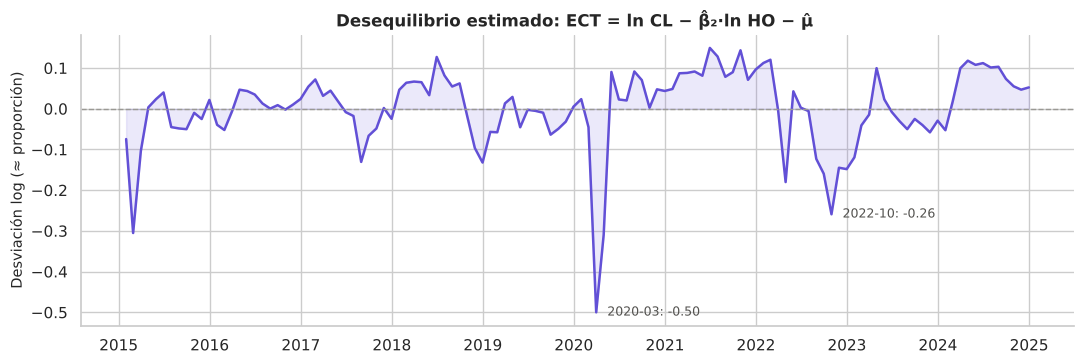

In [14]:
# --- Constante de la relación de equilibrio ---------------------------------------
# Con "co" la constante queda fuera de la relación. Para leerla dentro de ella estimamos
# la variante "ci" (constante restringida): β y α prácticamente no cambian.
res_ci = VECM(datos, k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic="ci").fit()
mu = res_ci.det_coef_coint[0, 0]
b2 = vecm_res.beta[1, 0]
print(f"β₂ con 'co': {b2:.4f}  |  β₂ con 'ci': {res_ci.beta[1, 0]:.4f}  |  constante en la relación ('ci'): {mu:.4f}")
print("\nRelación de largo plazo estimada:")
print(f"   ln CL = {-mu:.3f} + {-b2:.3f} · ln HO      (equivalente: ln HO = {mu / -b2:.3f} + {1 / -b2:.3f} · ln CL)")

# Término de corrección del error (desviación respecto al equilibrio)
ect = pd.Series(datos.values @ vecm_res.beta[:, 0], index=datos.index) + mu
print(f"\nMedia muestral del ECT (≈ 0 por construcción con 'ci'): {ect.mean():.4f}")
print(f"ECT en {ect.index[-1]:%Y-%m}: {ect.iloc[-1]:+.4f}")

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(ect.index, ect, color=COL["ECT"])
ax.axhline(0, color=COL["ref"], ls="--", lw=1)
ax.fill_between(ect.index, ect, 0, color=COL["ECT"], alpha=0.12)
ax.set_title("Desequilibrio estimado: ECT = ln CL − β̂₂·ln HO − μ̂ ")
ax.set_ylabel("Desviación log (≈ proporción)")
for anio in ("2020", "2022"):
    f = ect.loc[anio].idxmin()
    ax.annotate(f"{f:%Y-%m}: {ect.loc[f]:+.2f}", (f, ect.loc[f]), xytext=(8, 0), textcoords="offset points",
                fontsize=9, color="#52514e", va="center")
eje_fechas(ax)
plt.tight_layout(); plt.show()

### 7.1 Cómo leer $\hat\beta$

La relación estimada es aproximadamente $\ln CL = 3.51 + 0.845\,\ln HO$ (la constante proviene de la variante `"ci"`).

- **Ejemplo numérico 1 (elasticidad de largo plazo).** Si el gasóleo es un 10 % más caro, el precio de equilibrio del
  crudo es $0.845\times 10\% \approx 8.4\%$ más alto. Leído al revés, un crudo 10 % más caro se asocia con un gasóleo
  de equilibrio $\approx 11.8\%$ más caro ($1/0.845 \approx 1.18$).
- **Homogeneidad.** Si ambos precios se movieran uno a uno en el largo plazo, el diferencial logarítmico
  $\ln CL-\ln HO$ sería la relación de equilibrio ($\beta_2 = -1$). El intervalo de confianza al 95 % para $\beta_2$,
  aproximadamente $[-0.93,\,-0.75]$, **no contiene a −1**: con la muestra completa los datos no respaldan la homogeneidad
  estricta (el Módulo 8 muestra que este resultado depende de incluir 2022). El gráfico del *spread* simple del cuaderno
  original suponía implícitamente $\beta_2=-1$.
- **Normalización ≠ causalidad.** Escribir la relación "despejando" $\ln CL$ es una convención. No afirma que el gasóleo
  determine al crudo, ni lo contrario. Para identificar una relación estructural (por ejemplo, una ecuación de oferta de
  refinación) harían falta restricciones derivadas de la teoría, no una normalización.

### 7.2 Cómo leer $\hat\alpha$

Con la normalización $ECT = \ln CL - 0.845\ln HO - \mu$, un $ECT>0$ indica que el crudo está **caro relativo al gasóleo**.

- $\hat\alpha_{CL}\approx -0.175$ (p ≈ 0.16): el crudo tendería a bajar, pero el coeficiente **no es significativo**; no se
  rechaza que el crudo sea **débilmente exógeno** respecto a esta relación.
- $\hat\alpha_{HO}\approx +0.248$ (p ≈ 0.02): el gasóleo **sube** cuando el crudo está caro relativo a él. El signo positivo
  es exactamente el que corrige el desequilibrio con esta normalización. En el cuaderno original un $\alpha$ positivo
  se interpretaba como "revisar especificación": esa lectura era incorrecta.

**Ejemplo numérico 2 (corrección del desequilibrio).** Suponga que este mes el crudo está 10 % por encima de su
equilibrio ($ECT = 0.10$). El mes siguiente, en promedio, $\Delta\ln CL \approx -0.175\times 0.10 = -1.75\%$ y
$\Delta\ln HO \approx 0.248\times0.10 = +2.48\%$. El nuevo desequilibrio es
$0.10 - 0.0175 - 0.845\times 0.0248 \approx 0.0615$: se cierra ≈ 38.5 % de la brecha por mes, que es
$-\hat\beta'\hat\alpha$. El gasóleo hace la mayor parte del ajuste.

**Semivida.** Con `k_ar_diff = 0` (sin $\Gamma$), el desequilibrio sigue exactamente un AR(1):
$ECT_t = (1+\beta'\alpha)\,ECT_{t-1} + \beta'\varepsilon_t$. Por eso aquí la semivida se calcula con la dinámica completa del
sistema, no con un $\alpha$ aislado. La siguiente celda la calcula y la contrasta con una regresión AR(1) del ECT.

In [15]:
rho = 1 + beta_alpha
semivida = np.log(0.5) / np.log(rho)
print(f"Persistencia implícita 1 + β'α = {rho:.3f}  →  semivida = {semivida:.2f} meses")

# Contraste empírico: AR(1) del ECT estimado
e0, e1 = ect.values[:-1], ect.values[1:]
rho_emp = np.linalg.lstsq(np.column_stack([np.ones_like(e0), e0]), e1, rcond=None)[0][1]
print(f"AR(1) estimado directamente sobre el ECT: ρ = {rho_emp:.3f}  →  semivida = {np.log(0.5) / np.log(rho_emp):.2f} meses")

# Ejemplo numérico 2, calculado
ect0 = 0.10
d_cl, d_ho = vecm_res.alpha[:, 0] * ect0
print(f"\nCon ECT = 0.10: ΔlnCL = {d_cl:+.4f}, ΔlnHO = {d_ho:+.4f}, nuevo ECT = {ect0 + d_cl + b2 * d_ho:.4f}")

# Prueba formal de causalidad de Granger dentro del VECM (incluye el canal del ECT)
for causante, causada in ((0, 1), (1, 0)):
    g = vecm_res.test_granger_causality(caused=causada, causing=causante, signif=0.05)
    print(f"Granger: {ETIQ[datos.columns[causante]]} → {ETIQ[datos.columns[causada]]}:  p-valor = {g.pvalue:.4f}")

Persistencia implícita 1 + β'α = 0.615  →  semivida = 1.43 meses
AR(1) estimado directamente sobre el ECT: ρ = 0.615  →  semivida = 1.43 meses

Con ECT = 0.10: ΔlnCL = -0.0175, ΔlnHO = +0.0248, nuevo ECT = 0.0615
Granger: ln(crudo WTI) → ln(gasóleo):  p-valor = 0.0004
Granger: ln(gasóleo) → ln(crudo WTI):  p-valor = 0.9647


**Interpretación.** La persistencia implícita es ≈ 0.61 y la semivida ≈ 1.4 meses: la mitad de un desequilibrio
típico desaparece en algo más de un mes. La regresión AR(1) directa sobre el ECT da un valor muy parecido, lo que
confirma la coherencia interna. Esta semivida es válida **solo** porque el modelo no tiene rezagos en diferencias; con
$\Gamma\neq 0$ habría que derivarla de la función impulso-respuesta del ECT.

La prueba de Granger dentro del VECM rechaza la no causalidad del crudo hacia el gasóleo (p < 0.001) y no la rechaza en el
sentido contrario (p ≈ 0.96). Con `k_ar_diff = 0` la única vía por la que el pasado de una variable influye en la otra es el
término de corrección del error, así que el resultado es coherente con los $\alpha$: el gasóleo reacciona a la información
contenida en el nivel pasado del crudo; el crudo no reacciona de forma detectable al del gasóleo. **Causalidad de Granger es
precedencia predictiva, no causalidad económica.**

### 7.3 Dinámica de corto plazo ($\Gamma$)

Con la especificación principal no hay matrices $\Gamma$ (BIC eligió `k_ar_diff = 0`). Para que el estudiante sepa
leerlas, las mostramos para la alternativa elegida por AIC (`k_ar_diff = 2`).

In [16]:
res_aic = VECM(datos, k_ar_diff=sel.aic, coint_rank=1, deterministic=DETERMINISTICO).fit()
nombres_g = [f"Δ{ETIQ[c]} (t−{l})" for l in range(1, sel.aic + 1) for c in datos.columns]
gam = pd.DataFrame(res_aic.gamma, index=["ec. Δ" + ETIQ[c] for c in datos.columns], columns=nombres_g)
pg = pd.DataFrame(res_aic.pvalues_gamma, index=gam.index, columns=nombres_g)
print(f"Γ con k_ar_diff = {sel.aic} (coeficiente y, debajo, p-valor)")
display(pd.concat({"coef": gam, "p-valor": pg}).round(3))
print(f"Con k_ar_diff = {sel.aic}: α = {np.round(res_aic.alpha[:, 0], 3)}, p-valores = {np.round(res_aic.pvalues_alpha[:, 0], 3)}, "
      f"β₂ = {res_aic.beta[1, 0]:.3f}")

Γ con k_ar_diff = 2 (coeficiente y, debajo, p-valor)


Δln(crudo WTI) (t−1)  Δln(gasóleo) (t−1)  \
coef    ec. Δln(crudo WTI)                 0.339              -0.107   
        ec. Δln(gasóleo)                   0.253              -0.071   
p-valor ec. Δln(crudo WTI)                 0.028               0.529   
        ec. Δln(gasóleo)                   0.056               0.623   

                            Δln(crudo WTI) (t−2)  Δln(gasóleo) (t−2)  
coef    ec. Δln(crudo WTI)                -0.421               0.427  
        ec. Δln(gasóleo)                  -0.317               0.271  
p-valor ec. Δln(crudo WTI)                 0.005               0.005  
        ec. Δln(gasóleo)                   0.014               0.038

Con k_ar_diff = 2: α = [-0.292  0.145], p-valores = [0.056 0.265], β₂ = -0.814


**Cómo leer $\Gamma$.** Cada fila es una ecuación; cada columna, un cambio rezagado. Por ejemplo, el coeficiente de la
fila "ec. Δln(crudo)" y la columna "Δln(crudo) (t−1)" mide cuánto del cambio del crudo del mes pasado persiste en el
cambio de este mes, **manteniendo constante el desequilibrio**. Algunos coeficientes son significativos: en la ecuación
del crudo, el propio cambio del mes anterior (≈ +0.34) y, en el segundo rezago, coeficientes de signo opuesto y magnitud
parecida para crudo (≈ −0.42) y gasóleo (≈ +0.43), un patrón que reacciona a cambios pasados del **diferencial** entre ambos.
Aun así, BIC prefiere no incluirlos: la mejora de ajuste no compensa los 8 parámetros adicionales con $T=120$. AIC, más
permisivo, sí los incluye. Ninguna de las dos elecciones es "la verdadera"; por eso ambas se comparan en la validación.

Observe la última línea: con dos rezagos, $\hat\beta_2$ casi no cambia (≈ −0.81), pero **los $\alpha$ sí cambian** y ninguno
es claramente significativo al 5 %. La pregunta "¿qué precio corrige?" es **sensible a la especificación**; el Módulo 8 lo
documenta de forma sistemática. Esto es frecuente en la práctica: el vector de cointegración (superconsistente) se estima
con mucha más precisión que las velocidades de ajuste.

> **Errores frecuentes.** (1) Llamar "% de corrección por período" a un $\alpha$ individual. (2) Concluir que un $\alpha$
> positivo es un error sin mirar la normalización. (3) Leer $\Gamma$ como efectos totales: el efecto total de un choque
> combina $\Gamma$ y el mecanismo de corrección (por eso existen las IRF).

> **Comprueba tu comprensión.** Si normalizara $\beta$ sobre el gasóleo ($\beta_{HO}=1$), ¿qué signos esperaría para
> $\alpha_{CL}$ y $\alpha_{HO}$? Verifíquelo reordenando las columnas de `datos`.

---
## Módulo 8. Diagnóstico econométrico

**Objetivo de aprendizaje:** verificar los supuestos del VECM, identificar qué problemas tiene el modelo y valorar
cuánto afectan a las conclusiones.

Un VECM estimado por máxima verosimilitud gaussiana requiere, sobre todo, **residuos sin autocorrelación** (si la hay, la
prueba de Johansen y los errores estándar no son fiables). La normalidad y la homocedasticidad son menos críticas para
la consistencia, pero afectan la eficiencia y la validez de los intervalos de pronóstico.

> **Corrección respecto al original.** El estadístico Durbin-Watson próximo a 2 en cada ecuación no demuestra ausencia
> de autocorrelación en el sistema (solo mira el rezago 1, ecuación por ecuación, y no es válido con regresores
> rezagados). Aplicar ADF a los residuos tampoco es un diagnóstico útil: por construcción casi siempre "son I(0)". Aquí
> usamos la prueba Portmanteau multivariada y Ljung-Box por ecuación.

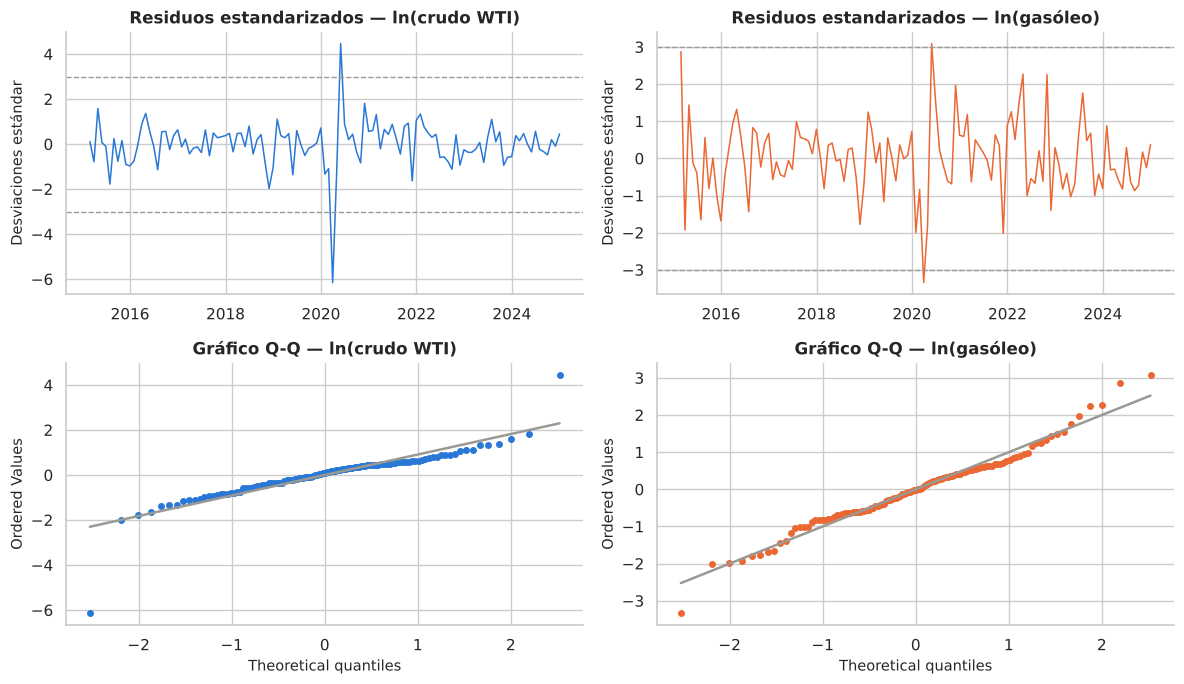

In [17]:
from statsmodels.stats.diagnostic import acorr_ljungbox

idx_res = datos.index[K_AR_DIFF + 1:]              # el VECM pierde k_ar_diff + 1 observaciones iniciales
residuos = pd.DataFrame(vecm_res.resid, index=idx_res, columns=datos.columns)
assert len(residuos) == vecm_res.nobs
z = (residuos - residuos.mean()) / residuos.std()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for j, c in enumerate(datos.columns):
    color = COL["CL"] if "CL" in c else COL["HO"]
    axes[0, j].plot(z.index, z[c], color=color, lw=1.1)
    for lim in (-3, 3):
        axes[0, j].axhline(lim, color=COL["ref"], ls="--", lw=1)
    axes[0, j].set_title(f"Residuos estandarizados — {ETIQ[c]}")
    axes[0, j].set_ylabel("Desviaciones estándar")
    eje_fechas(axes[0, j], 2)
    stats.probplot(z[c], dist="norm", plot=axes[1, j])
    axes[1, j].get_lines()[0].set(color=color, markersize=4)
    axes[1, j].get_lines()[1].set(color=COL["ref"])
    axes[1, j].set_title(f"Gráfico Q-Q — {ETIQ[c]}")
plt.tight_layout(); plt.show()

In [18]:
diag = []
w = vecm_res.test_whiteness(nlags=12, adjusted=True)
diag.append({"Prueba": "Portmanteau multivariada (12 rezagos, ajustada)", "H0": "sin autocorrelación conjunta",
             "Estadístico": w.test_statistic, "p-valor": w.pvalue})
for c, i in zip(datos.columns, range(2)):
    lb = acorr_ljungbox(residuos[c], lags=[12])
    diag.append({"Prueba": f"Ljung-Box 12 rezagos — {ETIQ[c]}", "H0": "sin autocorrelación",
                 "Estadístico": lb["lb_stat"].iloc[0], "p-valor": lb["lb_pvalue"].iloc[0]})
nrm = vecm_res.test_normality()
diag.append({"Prueba": "Jarque-Bera multivariada", "H0": "normalidad conjunta",
             "Estadístico": nrm.test_statistic, "p-valor": nrm.pvalue})
for c in datos.columns:
    lm, p_lm, _, _ = het_arch(residuos[c], nlags=6)
    diag.append({"Prueba": f"ARCH-LM 6 rezagos — {ETIQ[c]}", "H0": "varianza condicional constante",
                 "Estadístico": lm, "p-valor": p_lm})
tabla_diag = pd.DataFrame(diag)
tabla_diag["Decisión (5%)"] = np.where(tabla_diag["p-valor"] < 0.05, "rechaza H0", "no rechaza H0")
display(tabla_diag.round(4))

print("Asimetría y curtosis (exceso) de los residuos:")
display(pd.DataFrame({"asimetría": residuos.skew(), "curtosis exceso": residuos.kurt()}).round(2))
print("Observaciones con |residuo estandarizado| > 3:")
display(z[(z.abs() > 3).any(axis=1)].round(2))

,Prueba,H0,Estadístico,p-valor,Decisión (5%)
0,"Portmanteau multivariada (12 rezagos, ajustada)",sin autocorrelación conjunta,45.2558,0.5033,no rechaza H0
1,Ljung-Box 12 rezagos — ln(crudo WTI),sin autocorrelación,14.1652,0.2903,no rechaza H0
2,Ljung-Box 12 rezagos — ln(gasóleo),sin autocorrelación,15.6051,0.2100,no rechaza H0
3,Jarque-Bera multivariada,normalidad conjunta,1126.4713,0.0000,rechaza H0
4,ARCH-LM 6 rezagos — ln(crudo WTI),varianza condicional constante,26.1796,0.0002,rechaza H0
5,ARCH-LM 6 rezagos — ln(gasóleo),varianza condicional constante,19.2601,0.0037,rechaza H0


Asimetría y curtosis (exceso) de los residuos:


,asimetría,curtosis exceso
ln_CL,-1.32,14.06
ln_HO,0.13,1.33


Observaciones con |residuo estandarizado| > 3:


,ln_CL,ln_HO
fecha,,
2020-03-31,-6.15,-3.34
2020-05-31,4.47,3.09


**Interpretación.**

- **Autocorrelación:** la prueba Portmanteau y Ljung-Box no rechazan la ausencia de autocorrelación. `k_ar_diff = 0`
  parece suficiente para capturar la dinámica: la elección de BIC queda respaldada.
- **Normalidad:** se rechaza con fuerza. La causa es visible en los gráficos: colas pesadas, sobre todo en el crudo,
  dominadas por **marzo y mayo de 2020** (residuos de más de 3 desviaciones estándar).
- **Heterocedasticidad condicional:** ARCH-LM rechaza en ambas ecuaciones; la volatilidad se agrupa (2015-2016, 2020,
  2022). Los errores estándar de $\alpha$ y los intervalos de pronóstico gaussianos deben leerse con cautela.

**Implicaciones y alternativas.** La no normalidad no invalida la estimación de $\beta$ (que sigue siendo consistente),
pero sí los intervalos de pronóstico y puede afectar la prueba de Johansen en muestras pequeñas. Alternativas: variables
ficticias de impulso para los meses extremos (abajo), errores estándar robustos o *bootstrap*, y modelos con volatilidad
cambiante.

### 8.1 Estabilidad: raíces del sistema y estimaciones recursivas

En un VECM con $k=2$ y $r=1$ el VAR en niveles implícito debe tener **exactamente $k-r = 1$ raíz unitaria** y las demás
dentro del círculo unitario. Además, si la relación de equilibrio es estable, $\hat\beta_2$ estimado con muestras
crecientes no debería desplazarse de forma sistemática.

Módulos de los autovalores de la matriz compañera: [1.     0.6152]
(Con k_ar_diff = 0 deben ser 1 y 1 + β'α = 0.6152)


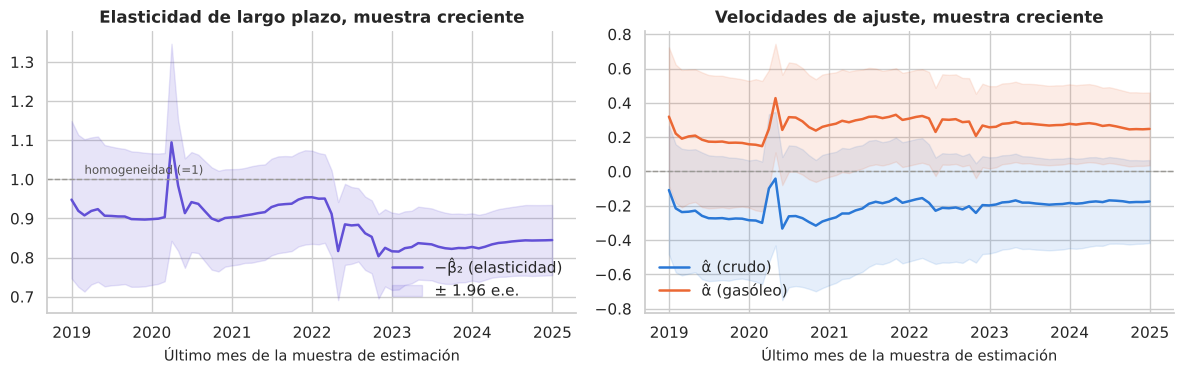

In [19]:
# Raíces de la forma compañera del VAR en niveles implícito
A = vecm_res.var_rep                 # (p, k, k)
p_var, k = A.shape[0], A.shape[1]
comp = np.zeros((k * p_var, k * p_var))
comp[:k, :] = np.hstack(list(A))
if p_var > 1:
    comp[k:, :-k] = np.eye(k * (p_var - 1))
mod_raices = np.sort(np.abs(np.linalg.eigvals(comp)))[::-1]
print("Módulos de los autovalores de la matriz compañera:", np.round(mod_raices, 4))
print(f"(Con k_ar_diff = 0 deben ser 1 y 1 + β'α = {1 + beta_alpha:.4f})")

# Estimaciones recursivas (ventana expansiva)
rec = []
for fin in datos.loc["2018-12":].index:
    r_ = VECM(datos.loc[:fin], k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic=DETERMINISTICO).fit()
    rec.append({"fin": fin, "beta2": r_.beta[1, 0], "se_b": r_.stderr_beta[1, 0],
                "a_CL": r_.alpha[0, 0], "se_aCL": r_.stderr_alpha[0, 0],
                "a_HO": r_.alpha[1, 0], "se_aHO": r_.stderr_alpha[1, 0]})
rec = pd.DataFrame(rec).set_index("fin")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(rec.index, -rec["beta2"], color=COL["ECT"], label="−β̂₂ (elasticidad)")
axes[0].fill_between(rec.index, -rec["beta2"] - 1.96 * rec["se_b"], -rec["beta2"] + 1.96 * rec["se_b"],
                     color=COL["ECT"], alpha=0.15, label="± 1.96 e.e.")
axes[0].axhline(1, color=COL["ref"], ls="--", lw=1)
axes[0].annotate("homogeneidad (=1)", (rec.index[2], 1.0), xytext=(0, 4), textcoords="offset points",
                 fontsize=8.5, color="#52514e")
axes[0].set_title("Elasticidad de largo plazo, muestra creciente"); axes[0].legend(loc="lower right")
for nombre, se, col in (("a_CL", "se_aCL", COL["CL"]), ("a_HO", "se_aHO", COL["HO"])):
    axes[1].plot(rec.index, rec[nombre], color=col, label=f"α̂ ({'crudo' if 'CL' in nombre else 'gasóleo'})")
    axes[1].fill_between(rec.index, rec[nombre] - 1.96 * rec[se], rec[nombre] + 1.96 * rec[se], color=col, alpha=0.12)
axes[1].axhline(0, color=COL["ref"], ls="--", lw=1)
axes[1].set_title("Velocidades de ajuste, muestra creciente"); axes[1].legend(loc="lower left")
for ax in axes:
    ax.set_xlabel("Último mes de la muestra de estimación"); eje_fechas(ax)
plt.tight_layout(); plt.show()

**Interpretación.** Los módulos de las raíces son 1 (la tendencia común) y ≈ 0.61 (la persistencia del desequilibrio):
el sistema es estable en el sentido que exige un VECM con una relación de cointegración.

Las estimaciones recursivas muestran que la elasticidad de largo plazo se mueve entre ≈ 0.80 y ≈ 0.95, con un salto
puntual (≈ 1.09) al incorporar marzo de 2020. Hasta 2021 la banda de ±1.96 errores estándar **incluye el 1**, es decir,
con la muestra previa a 2022 no se habría rechazado la homogeneidad; solo al añadir 2022 la elasticidad baja a ≈ 0.82-0.85 y
la banda excluye el 1. Los coeficientes de ajuste son más inestables: la banda del crudo incluye el cero con cualquier
muestra, y la del gasóleo excluye el cero en casi todas las muestras que terminan después de abril de 2021 (con dos
excepciones en 2022), pero no en las anteriores. No es una prueba formal de
cambio estructural, pero advierte que **la homogeneidad y "quién ajusta" dependen del período**, en especial de 2022, cuando
el margen de refinación de destilados alcanzó máximos históricos.

### 8.2 Sensibilidad a rezagos, términos deterministas y observaciones extremas

In [20]:
# Variables ficticias de impulso para los meses extremos de 2020
dummies = pd.DataFrame(0.0, index=datos.index, columns=["d2020_03", "d2020_04", "d2020_05"])
for col, f in zip(dummies.columns, ["2020-03-31", "2020-04-30", "2020-05-31"]):
    dummies.loc[f, col] = 1.0

filas = []
for kd in (0, 1, 2):
    for det in ("co", "ci"):
        for con_d in (False, True):
            r_ = VECM(datos, exog=dummies if con_d else None, k_ar_diff=kd, coint_rank=1, deterministic=det).fit()
            filas.append({"k_ar_diff": kd, "determ.": det, "dummies 2020": "sí" if con_d else "no",
                          "−β₂": -r_.beta[1, 0],
                          "α crudo": r_.alpha[0, 0], "p α crudo": r_.pvalues_alpha[0, 0],
                          "α gasóleo": r_.alpha[1, 0], "p α gasóleo": r_.pvalues_alpha[1, 0],
                          "β'α": (r_.beta.T @ r_.alpha).item(),
                          "p Portmanteau": r_.test_whiteness(nlags=12, adjusted=True).pvalue,
                          "p normalidad": r_.test_normality().pvalue})
sens_vecm = pd.DataFrame(filas)
display(sens_vecm.round(3))

,k_ar_diff,determ.,dummies 2020,−β₂,α crudo,p α crudo,α gasóleo,p α gasóleo,β'α,p Portmanteau,p normalidad
0,0,co,no,0.845,-0.175,0.155,0.248,0.022,-0.385,0.503,0.0
1,0,co,sí,0.844,-0.104,0.323,0.231,0.050,-0.299,0.777,0.0
2,0,ci,no,0.845,-0.175,0.155,0.248,0.022,-0.385,0.505,0.0
3,0,ci,sí,0.845,-0.101,0.339,0.234,0.047,-0.299,0.783,0.0
4,1,co,no,0.819,-0.389,0.004,0.103,0.376,-0.473,0.597,0.0
5,1,co,sí,0.819,-0.155,0.178,0.206,0.096,-0.324,0.742,0.0
6,1,ci,no,0.819,-0.389,0.004,0.103,0.376,-0.473,0.598,0.0
7,1,ci,sí,0.819,-0.158,0.167,0.202,0.102,-0.324,0.747,0.0
8,2,co,no,0.814,-0.292,0.056,0.145,0.265,-0.410,0.861,0.0
9,2,co,sí,0.810,-0.183,0.139,0.141,0.286,-0.297,0.779,0.0


**Lectura de la tabla de sensibilidad.**

- **$\beta$ es robusto:** la elasticidad $-\beta_2$ se mueve entre ≈ 0.81 y ≈ 0.85 en todas las variantes. Pasar de `"co"`
  a `"ci"` no altera nada relevante, y las ficticias de 2020 tampoco.
- **$\alpha$ no es robusto:** con 0 rezagos ajusta el gasóleo; con 1 rezago (la especificación del cuaderno original) ajusta
  el crudo y el gasóleo deja de ser significativo; con 2 rezagos ninguno es claramente significativo al 5 %. Con ficticias, el
  ajuste del gasóleo queda en el límite del 5 %. En todas las variantes $\beta'\alpha < 0$: **el sistema corrige**, aunque
  no podamos atribuir con seguridad la corrección a uno de los dos mercados.
- **Autocorrelación:** no se detecta en ninguna variante.
- **Normalidad:** se rechaza incluso con las ficticias de 2020; quedan colas pesadas en otros meses.

### 8.3 Resumen del diagnóstico

| Aspecto | Hallazgo | Implicación | Respuesta posible |
|---|---|---|---|
| Autocorrelación residual | No detectada | La elección `k_ar_diff = 0` es aceptable | — |
| Normalidad | Rechazada (colas pesadas, 2020) | Intervalos de pronóstico gaussianos poco fiables | *Bootstrap*, ficticias, distribución $t$ |
| Heterocedasticidad (ARCH) | Presente | Errores estándar de $\alpha$ con cautela | Errores robustos, modelos de volatilidad |
| Estabilidad de $\beta$ | Razonable | La relación de largo plazo es la conclusión más sólida | — |
| Estabilidad de $\alpha$ | Baja | "Quién ajusta" depende de rezagos y período | Reportar como hallazgo tentativo |
| Rango $r=1$ vs. $r=2$ | Evidencia límite | Riesgo de mala especificación | Comparar con VAR en niveles (Módulo 10) |

> **Comprueba tu comprensión.** ¿Por qué tiene sentido que $\beta$ sea más estable que $\alpha$? (Pista: velocidad de
> convergencia de los estimadores de cointegración.)

---
## Módulo 9. Análisis dinámico: funciones impulso-respuesta y descomposición de varianza

**Objetivo de aprendizaje:** interpretar cómo se propagan los choques en un sistema cointegrado y entender los supuestos
que hay detrás de cada gráfico.

### 9.1 Qué es un impulso y qué es una respuesta

Un **impulso** es un choque inesperado de una unidad (o de una desviación estándar) en el error de una ecuación en el
período 0. La **respuesta** es la diferencia entre la trayectoria esperada de cada variable con y sin ese choque, para
los horizontes $h=0,1,2,\dots$

- **IRF no ortogonalizadas:** choque de una unidad en $\varepsilon_{j}$ manteniendo los demás errores en cero. Problema:
  los errores están correlacionados (aquí, fuertemente), de modo que "un choque al crudo sin choque al gasóleo" es un
  experimento poco realista.
- **IRF ortogonalizadas (Cholesky):** se descompone $\boldsymbol\Sigma = \mathbf P\mathbf P'$ con $\mathbf P$ triangular inferior
  y se usan choques $\mathbf u_t = \mathbf P^{-1}\boldsymbol\varepsilon_t$ no correlacionados. La primera variable del orden
  afecta a todas en el mismo mes; la segunda no afecta a la primera en $h=0$. **El orden es un supuesto de identificación**.
  Ponemos primero al crudo (mercado global, insumo) y segundo al gasóleo; luego verificamos qué cambia al invertir el orden.

### 9.2 Diferencia clave con un VAR estacionario

En un sistema $I(1)$ cointegrado los choques **no se desvanecen**: tienen efectos permanentes sobre los niveles. Lo que
sí se desvanece es el efecto sobre el **desequilibrio**: a largo plazo ambas respuestas deben satisfacer la relación de
cointegración, $\beta'\,\mathbf{IRF}(\infty) = 0$.

> **Corrección respecto al original.** El cuaderno original calculaba las IRF y la FEVD con un VAR en primeras
> diferencias y las presentaba como si fueran del VECM. Ese VAR ignora el término de corrección del error, de modo que
> sus respuestas (sobre las tasas de cambio) no son las del modelo estimado. Además, describía bandas de confianza
> "bootstrap" que no correspondían al modelo. Aquí usamos `vecm_res.irf()`. `statsmodels` no calcula bandas de confianza
> para las IRF de un VECM, así que **no se muestran bandas**; interprete las curvas como estimaciones puntuales.

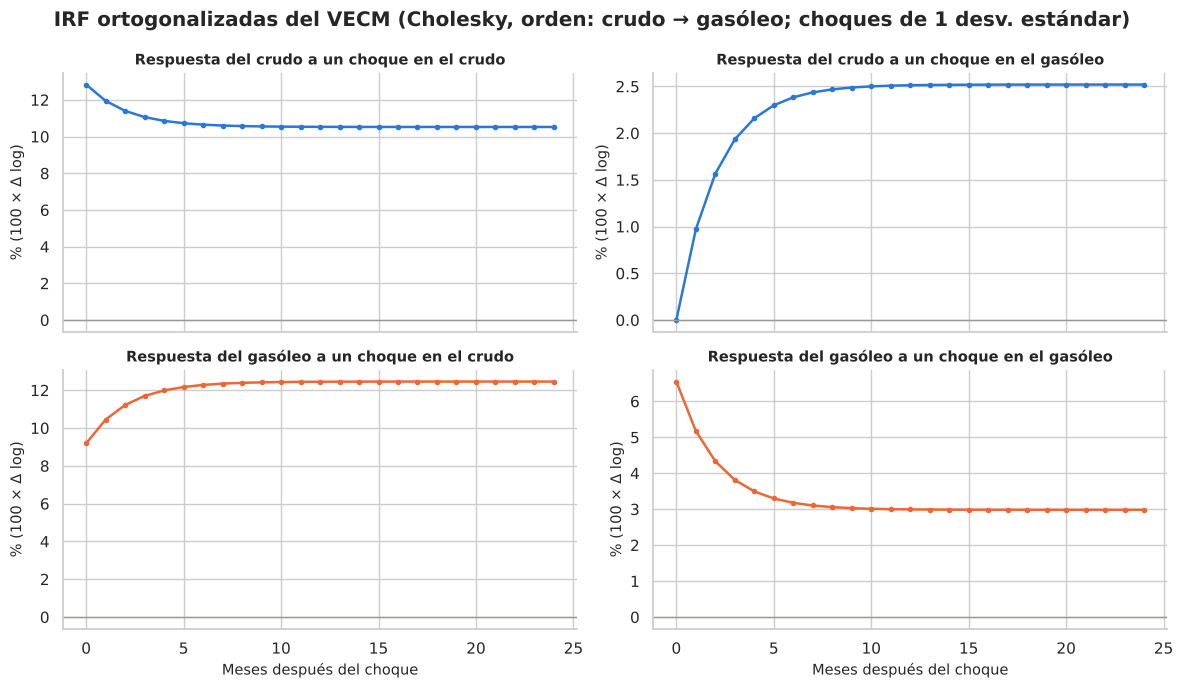

Respuestas ortogonalizadas en % (horizontes seleccionados):


,h=0,h=1,h=3,h=6,h=12,h=24
crudo ← choque crudo,12.84,11.95,11.06,10.65,10.53,10.53
gasóleo ← choque crudo,9.19,10.45,11.70,12.28,12.45,12.46
crudo ← choque gasóleo,0.00,0.97,1.93,2.38,2.51,2.52
gasóleo ← choque gasóleo,6.55,5.18,3.81,3.18,2.99,2.98


β' · IRF no ortogonalizada en h = 24 (debe ser ≈ 0): [[ 1.e-05 -1.e-05]]
Cociente de respuestas de largo plazo gasóleo/crudo ante choque al crudo: 1.184  (1/−β₂ = 1.184)


In [21]:
H_IRF = 24
irf_vecm = vecm_res.irf(periods=H_IRF)
oirf = irf_vecm.orth_irfs        # (H+1, respuesta, choque)
horiz = np.arange(H_IRF + 1)
nombres_cortos = {"ln_CL": "crudo", "ln_HO": "gasóleo"}
cols = list(datos.columns)

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for i, resp in enumerate(cols):
    for j, choque in enumerate(cols):
        ax = axes[i, j]
        ax.plot(horiz, 100 * oirf[:, i, j], color=COL["CL"] if "CL" in resp else COL["HO"], marker="o", ms=3)
        ax.axhline(0, color=COL["ref"], lw=1)
        ax.set_title(f"Respuesta del {nombres_cortos[resp]} a un choque en el {nombres_cortos[choque]}", fontsize=10.5)
        ax.set_ylabel("% (100 × Δ log)")
axes[1, 0].set_xlabel("Meses después del choque"); axes[1, 1].set_xlabel("Meses después del choque")
fig.suptitle("IRF ortogonalizadas del VECM (Cholesky, orden: crudo → gasóleo; choques de 1 desv. estándar)", fontweight="bold")
plt.tight_layout(); plt.show()

resumen_irf = pd.DataFrame({
    f"h={h}": [100 * oirf[h, 0, 0], 100 * oirf[h, 1, 0], 100 * oirf[h, 0, 1], 100 * oirf[h, 1, 1]] for h in (0, 1, 3, 6, 12, 24)
}, index=["crudo ← choque crudo", "gasóleo ← choque crudo", "crudo ← choque gasóleo", "gasóleo ← choque gasóleo"])
print("Respuestas ortogonalizadas en % (horizontes seleccionados):")
display(resumen_irf.round(2))

# Verificación: a largo plazo las respuestas respetan la relación de equilibrio (β' · IRF(∞) ≈ 0)
lp = irf_vecm.irfs[-1]
print("β' · IRF no ortogonalizada en h = 24 (debe ser ≈ 0):", np.round(vecm_res.beta.T @ lp, 5))
print(f"Cociente de respuestas de largo plazo gasóleo/crudo ante choque al crudo: "
      f"{oirf[-1, 1, 0] / oirf[-1, 0, 0]:.3f}  (1/−β₂ = {1 / -b2:.3f})")

**Interpretación.**

- **Choque en el crudo (columna izquierda).** Un choque de una desviación estándar eleva el crudo ≈ 12.8 % en el
  impacto y el gasóleo ≈ 9.2 % ese mismo mes (por la correlación contemporánea que asigna Cholesky). Después, el crudo
  retrocede parcialmente y el gasóleo sigue subiendo, hasta estabilizarse en unos pocos meses: ≈ +10.5 % el crudo y
  ≈ +12.5 % el gasóleo. **El efecto es permanente**, como corresponde a series $I(1)$.
- **Choque en el gasóleo (columna derecha).** Por construcción no afecta al crudo en $h=0$. Su efecto permanente es
  pequeño (≈ 2.5-3 %): la mayor parte de un choque propio del gasóleo es transitoria, porque el gasóleo es el que ajusta
  hacia el equilibrio.
- **Coherencia con el largo plazo.** El cociente de las respuestas de largo plazo coincide con $1/(-\hat\beta_2)\approx 1.18$
  y $\hat\beta'\,\mathrm{IRF}(24)\approx 0$: los choques mueven los niveles pero no el desequilibrio de largo plazo.
- **Horizonte.** La transición se completa en 3-6 meses, coherente con una semivida de ≈ 1.4 meses; más allá de un año
  las curvas son planas.

### 9.3 ¿Cuánto depende del orden de Cholesky?

In [22]:
datos_inv = datos[["ln_HO", "ln_CL"]]
res_inv = VECM(datos_inv, k_ar_diff=K_AR_DIFF, coint_rank=1, deterministic=DETERMINISTICO).fit()
oirf_inv = res_inv.irf(periods=H_IRF).orth_irfs     # orden: gasóleo → crudo

corr_res = np.corrcoef(vecm_res.resid.T)[0, 1]
comp_orden = pd.DataFrame({
    "Orden crudo→gasóleo": [100 * oirf[0, 1, 0], 100 * oirf[-1, 1, 0], 100 * oirf[0, 0, 1], 100 * oirf[-1, 0, 1]],
    "Orden gasóleo→crudo": [100 * oirf_inv[0, 0, 1], 100 * oirf_inv[-1, 0, 1], 100 * oirf_inv[0, 1, 0], 100 * oirf_inv[-1, 1, 0]],
}, index=["gasóleo ← choque crudo (h=0)", "gasóleo ← choque crudo (h=24)",
          "crudo ← choque gasóleo (h=0)", "crudo ← choque gasóleo (h=24)"])
print(f"Correlación entre los residuos de las dos ecuaciones: {corr_res:.3f}")
display(comp_orden.round(2))

Correlación entre los residuos de las dos ecuaciones: 0.814


,Orden crudo→gasóleo,Orden gasóleo→crudo
gasóleo ← choque crudo (h=0),9.19,0.00
gasóleo ← choque crudo (h=24),12.46,4.80
crudo ← choque gasóleo (h=0),0.00,10.45
crudo ← choque gasóleo (h=24),2.52,10.03


**Interpretación.** La correlación contemporánea entre los errores es alta (≈ 0.81), así que el orden importa mucho:
con el gasóleo primero, un choque en el gasóleo pasa a mover al crudo de inmediato y con efecto permanente grande, y el
"choque del crudo" se reduce a su componente no explicado por el gasóleo. **Las dos versiones son matemáticamente
válidas; lo que cambia es el supuesto de identificación**, que debe justificarse con argumentos económicos (aquí, que el
crudo se forma en un mercado global más amplio). Ninguna de las dos es una prueba de causalidad.

### 9.4 Descomposición de la varianza del error de pronóstico (FEVD)

La FEVD responde: del error cuadrático medio de pronosticar la variable $i$ a $h$ meses, ¿qué proporción se debe a
cada choque ortogonalizado? Con las respuestas ortogonalizadas $\theta_{ij}(s)$:

$$\omega_{ij}(h) = \frac{\sum_{s=0}^{h-1}\theta_{ij}(s)^2}{\sum_{m=1}^{k}\sum_{s=0}^{h-1}\theta_{im}(s)^2}.$$

`statsmodels` no ofrece `fevd()` para resultados VECM. La calculamos a partir de `orth_irfs` del propio VECM, que es la
representación de medias móviles de los **niveles** implícita en el modelo (válida a horizonte finito aunque las series
sean $I(1)$). Antes de usarla, verificamos la función contra la implementación de `statsmodels` en un VAR.

¿Coincide con statsmodels en un VAR? True


,h=1,h=3,h=6,h=12,h=24
% var. del crudo por choque del crudo,100.0,99.2,97.9,96.5,95.6
% var. del gasóleo por choque del crudo,66.3,78.3,85.6,90.1,92.4


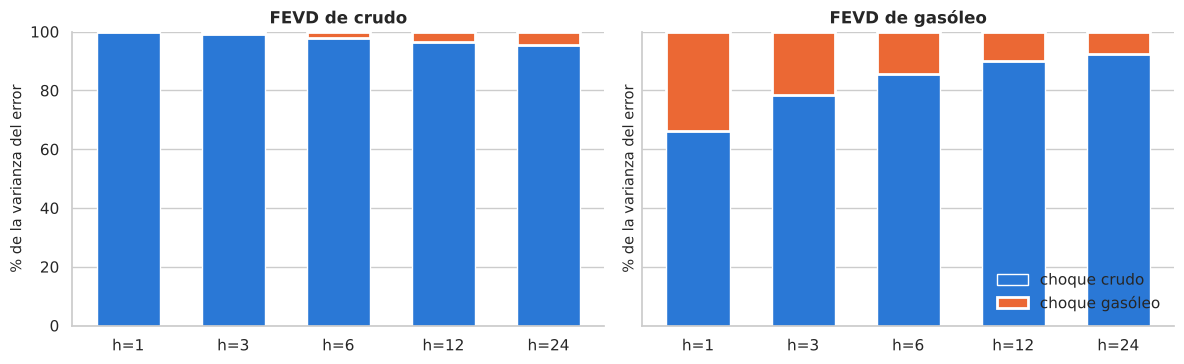

In [23]:
def fevd_desde_oirf(orth_irfs):
    # FEVD a partir de respuestas ortogonalizadas: devuelve (H, respuesta, choque); fila h-1 = horizonte h
    acumulado = np.cumsum(orth_irfs ** 2, axis=0)
    return acumulado / acumulado.sum(axis=2, keepdims=True)

# Verificación de la función con un VAR en niveles, donde statsmodels sí implementa fevd()
var_chk = VAR(datos).fit(1)
fevd_sm = np.transpose(var_chk.fevd(H_IRF).decomp, (1, 0, 2))
fevd_propia = fevd_desde_oirf(var_chk.irf(H_IRF).orth_irfs)[:H_IRF]
print("¿Coincide con statsmodels en un VAR?", np.allclose(fevd_sm, fevd_propia))

fevd_vecm = fevd_desde_oirf(oirf)
hs = [1, 3, 6, 12, 24]
tabla_fevd = pd.DataFrame(
    {f"h={h}": [100 * fevd_vecm[h - 1, 0, 0], 100 * fevd_vecm[h - 1, 1, 0]] for h in hs},
    index=["% var. del crudo por choque del crudo", "% var. del gasóleo por choque del crudo"])
display(tabla_fevd.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for i, resp in enumerate(cols):
    sh_cl = 100 * fevd_vecm[np.array(hs) - 1, i, 0]
    x = np.arange(len(hs))
    axes[i].bar(x, sh_cl, color=COL["CL"], label="choque crudo", width=0.6)
    axes[i].bar(x, 100 - sh_cl, bottom=sh_cl, color=COL["HO"], label="choque gasóleo", width=0.6, edgecolor="white", lw=2)
    axes[i].set_xticks(x, [f"h={h}" for h in hs]); axes[i].set_ylim(0, 100)
    axes[i].set_title(f"FEVD de {nombres_cortos[resp]}"); axes[i].set_ylabel("% de la varianza del error")
axes[1].legend(loc="lower right")
plt.tight_layout(); plt.show()

**Interpretación.** La función propia reproduce exactamente la FEVD de `statsmodels` en el caso de prueba, lo que
respalda su uso con el VECM. Con el orden crudo → gasóleo, los choques del crudo explican casi toda la varianza del
error de pronóstico del crudo y una proporción creciente de la del gasóleo: ≈ 66 % a un mes y más del 90 % a 12-24 meses.
Es la contrapartida de lo visto en las IRF: los choques propios del gasóleo son mayormente transitorios y, a horizontes
largos, la incertidumbre de ambos precios la domina la tendencia común asociada al crudo. **Esta conclusión hereda el
supuesto de orden de Cholesky**; con el orden inverso las proporciones cambian sustancialmente (ejercicio 12.6).

> **Errores frecuentes.** (1) Calcular IRF/FEVD con un VAR en diferencias y atribuirlas al VECM. (2) Dibujar bandas de
> confianza que el código no calculó. (3) Leer una FEVD de Cholesky como "porcentaje causado por".

> **Comprueba tu comprensión.** ¿Por qué en un VECM las IRF de los niveles no vuelven a cero, mientras que en un VAR
> estacionario sí?

---
## Módulo 10. Pronóstico y validación temporal

**Objetivo de aprendizaje:** evaluar la capacidad predictiva fuera de muestra con un diseño que evite filtraciones de
información futura, y comparar el VECM con alternativas razonables.

### 10.1 Diseño

| Conjunto | Período | Uso |
|---|---|---|
| **Entrenamiento** | 2015-01 a 2021-12 (84 meses) | Estimación inicial de todos los modelos |
| **Validación** | 2022-01 a 2023-06 (18 meses) | Elegir el número de rezagos de cada familia de modelos |
| **Prueba** | 2023-07 a 2024-12 (18 meses) | Evaluación final, una sola vez, con las configuraciones ya elegidas |

**Origen móvil con ventana expansiva.** Para cada mes de origen $t_0$ del período evaluado se reestima cada modelo con
datos **hasta $t_0-1$** y se pronostican $h = 1,\dots,6$ meses. Solo se usan pronósticos cuyo objetivo cae dentro del período
evaluado. Así cada pronóstico usa únicamente información disponible en su momento.

**Modelos comparados** (todos en logaritmos; el error se mide en puntos logarítmicos, ≈ error porcentual):

1. **VECM** con $r = 1$ y `k_ar_diff` ∈ {0, 1, 2}.
2. **VAR en primeras diferencias** con $p$ ∈ {1, 2, 3} (coherente con $r = 0$).
3. **VAR en niveles** con $p$ ∈ {1, 2, 3} (coherente con $r = 2$; lo incluimos porque el rango 1 vs. 2 quedó en duda).
4. **Ingenuo (paseo aleatorio):** el pronóstico es el último valor observado.

Sobre posibles filtraciones: el rango $r=1$ se decidió con la muestra completa. Por eso el diseño compara modelos
coherentes con los tres rangos posibles y elige rezagos solo con la validación; ningún parámetro se estima con datos del
período de prueba.

Entrenamiento: 84 meses | validación: 18 | prueba: 18


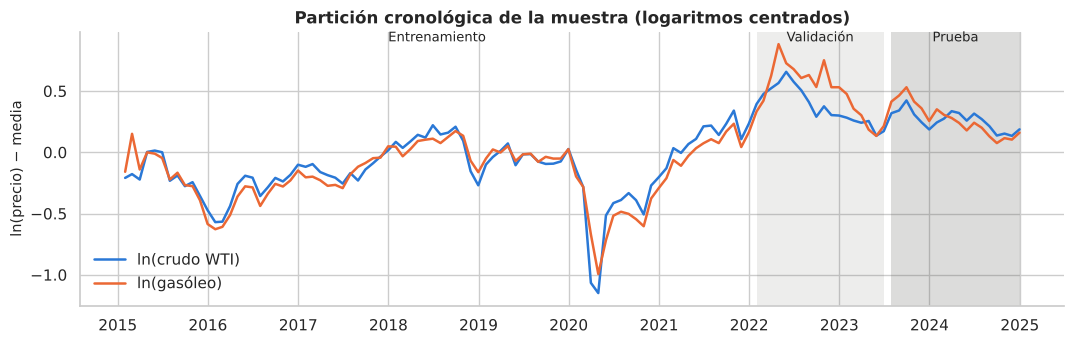

In [24]:
FIN_TRAIN, FIN_VAL = pd.Timestamp("2021-12-31"), pd.Timestamp("2023-06-30")
INI_VAL, INI_TEST, FIN_TEST = pd.Timestamp("2022-01-31"), pd.Timestamp("2023-07-31"), datos.index[-1]
H_MAX = 6
print(f"Entrenamiento: {(datos.index <= FIN_TRAIN).sum()} meses | "
      f"validación: {((datos.index >= INI_VAL) & (datos.index <= FIN_VAL)).sum()} | "
      f"prueba: {(datos.index >= INI_TEST).sum()}")

fig, ax = plt.subplots(figsize=(11, 3.6))
for c in cols:
    ax.plot(datos.index, datos[c] - datos[c].mean(), color=COL["CL"] if "CL" in c else COL["HO"], label=ETIQ[c])
for ini, fin, txt, a in ((datos.index[0], FIN_TRAIN, "Entrenamiento", 0.0), (INI_VAL, FIN_VAL, "Validación", 0.10),
                         (INI_TEST, FIN_TEST, "Prueba", 0.20)):
    ax.axvspan(ini, fin, color="#52514e", alpha=a, lw=0)
    ax.text(ini + (fin - ini) / 2, ax.get_ylim()[1] * 0.92, txt, ha="center", fontsize=9.5, color="#222")
ax.set_title("Partición cronológica de la muestra (logaritmos centrados)"); ax.set_ylabel("ln(precio) − media")
ax.legend(loc="lower left"); eje_fechas(ax)
plt.tight_layout(); plt.show()

In [25]:
def pronosticar(modelo, param, hist, h):
    # Devuelve un arreglo (h, 2) de pronósticos en logaritmos usando solo 'hist'.
    if modelo == "VECM":
        return VECM(hist, k_ar_diff=param, coint_rank=1, deterministic=DETERMINISTICO).fit().predict(steps=h)
    if modelo == "VAR_dif":
        dh = hist.diff().dropna()
        r = VAR(dh).fit(param, trend="c")
        return hist.values[-1] + np.cumsum(r.forecast(dh.values[-param:], h), axis=0)
    if modelo == "VAR_niv":
        r = VAR(hist).fit(param, trend="c")
        return r.forecast(hist.values[-param:], h)
    if modelo == "Ingenuo":
        return np.repeat(hist.values[-1:], h, axis=0)
    raise ValueError(modelo)

def origen_movil(modelo, param, inicio, fin, h_max=H_MAX):
    # Pronósticos de origen móvil (ventana expansiva) con objetivos dentro de [inicio, fin]
    filas, idx = [], datos.index
    for origen in idx[(idx >= inicio) & (idx <= fin)]:
        pos = idx.get_loc(origen)
        hist = datos.iloc[:pos]                       # información disponible: hasta el mes anterior al origen
        f = pronosticar(modelo, param, hist, h_max)
        for h in range(h_max):
            if pos + h < len(idx) and idx[pos + h] <= fin:
                real = datos.iloc[pos + h].values
                filas.append({"modelo": modelo, "param": param, "origen": origen, "objetivo": idx[pos + h], "h": h + 1,
                              "pred_CL": f[h, 0], "pred_HO": f[h, 1], "e_CL": real[0] - f[h, 0], "e_HO": real[1] - f[h, 1]})
    return pd.DataFrame(filas)

CANDIDATOS = {"VECM": [0, 1, 2], "VAR_dif": [1, 2, 3], "VAR_niv": [1, 2, 3], "Ingenuo": [0]}
val = pd.concat([origen_movil(m, p, INI_VAL, FIN_VAL) for m, ps in CANDIDATOS.items() for p in ps], ignore_index=True)
val["ecm"] = (val["e_CL"] ** 2 + val["e_HO"] ** 2) / 2
rmse_val = val.groupby(["modelo", "param"])["ecm"].mean().pipe(np.sqrt).rename("RMSE validación (prom. 2 variables, h=1..6)")
display(rmse_val.to_frame().round(4))

elegidos = rmse_val.groupby(level="modelo").idxmin().map(lambda t: t[1]).to_dict()
print("Configuración elegida en validación:", elegidos)

RMSE validación (prom. 2 variables, h=1..6)
modelo  param                                             
Ingenuo 0                                           0.2082
VAR_dif 1                                           0.2239
        2                                           0.2389
        3                                           0.2431
VAR_niv 1                                           0.2210
        2                                           0.2554
        3                                           0.2427
VECM    0                                           0.2110
        1                                           0.2678
        2                                           0.2579

Configuración elegida en validación: {'Ingenuo': 0, 'VAR_dif': 1, 'VAR_niv': 1, 'VECM': 0}


**Lectura de la validación.** Dentro de cada familia se elige la configuración con menor RMSE promedio (dos variables,
horizontes 1-6). Fíjese en dos hechos: el modelo **ingenuo** es tan bueno o mejor que todos los demás en este período,
y el VECM con `k_ar_diff = 0` es el mejor VECM. El período de validación (2022-2023) incluye la volatilidad
extrema posterior a la invasión de Ucrania, difícil para cualquier modelo.

### 10.2 Evaluación final en el conjunto de prueba

Errores en puntos logarítmicos (0.10 ≈ 10 %), todos los horizontes 1-6:


,MAE crudo,RMSE crudo,MAE gasóleo,RMSE gasóleo,n pronósticos,RMSE relativo al ingenuo (prom.)
VAR_niv,0.0721,0.0904,0.0813,0.1043,93.0,0.8858
Ingenuo,0.0832,0.1007,0.0991,0.1191,93.0,1.0000
VAR_dif,0.0912,0.1115,0.1086,0.1302,93.0,1.0998
VECM,0.0787,0.0973,0.1248,0.1465,93.0,1.1095


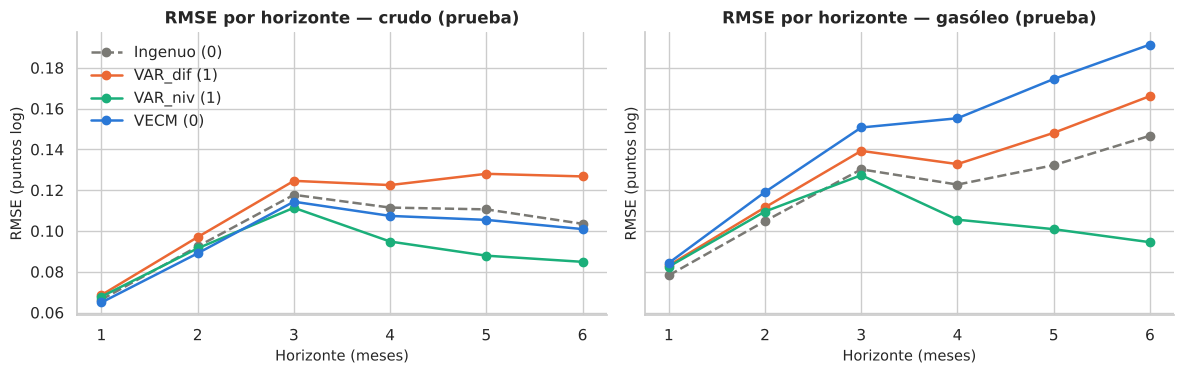

In [26]:
test = pd.concat([origen_movil(m, p, INI_TEST, FIN_TEST) for m, p in elegidos.items()], ignore_index=True)

def metricas(df):
    return pd.Series({"MAE crudo": df["e_CL"].abs().mean(), "RMSE crudo": np.sqrt((df["e_CL"] ** 2).mean()),
                      "MAE gasóleo": df["e_HO"].abs().mean(), "RMSE gasóleo": np.sqrt((df["e_HO"] ** 2).mean()),
                      "n pronósticos": len(df)})

tabla_test = pd.DataFrame({m: metricas(g) for m, g in test.groupby("modelo")}).T
tabla_test["RMSE relativo al ingenuo (prom.)"] = (
    (tabla_test["RMSE crudo"] + tabla_test["RMSE gasóleo"]) /
    (tabla_test.loc["Ingenuo", "RMSE crudo"] + tabla_test.loc["Ingenuo", "RMSE gasóleo"]))
print("Errores en puntos logarítmicos (0.10 ≈ 10 %), todos los horizontes 1-6:")
display(tabla_test.sort_values("RMSE relativo al ingenuo (prom.)").round(4))

rmse_h = (test.assign(crudo=test["e_CL"] ** 2, gasóleo=test["e_HO"] ** 2)
          .groupby(["modelo", "h"])[["crudo", "gasóleo"]].mean().pipe(np.sqrt))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, var in zip(axes, ["crudo", "gasóleo"]):
    for mod in elegidos:
        serie = rmse_h.loc[mod, var]
        ax.plot(serie.index, serie.values, marker="o", color=COL[mod], label=f"{mod} ({elegidos[mod]})",
                ls="--" if mod == "Ingenuo" else "-")
    ax.set_title(f"RMSE por horizonte — {var} (prueba)"); ax.set_xlabel("Horizonte (meses)")
    ax.set_ylabel("RMSE (puntos log)")
axes[0].legend(loc="upper left")
plt.tight_layout(); plt.show()

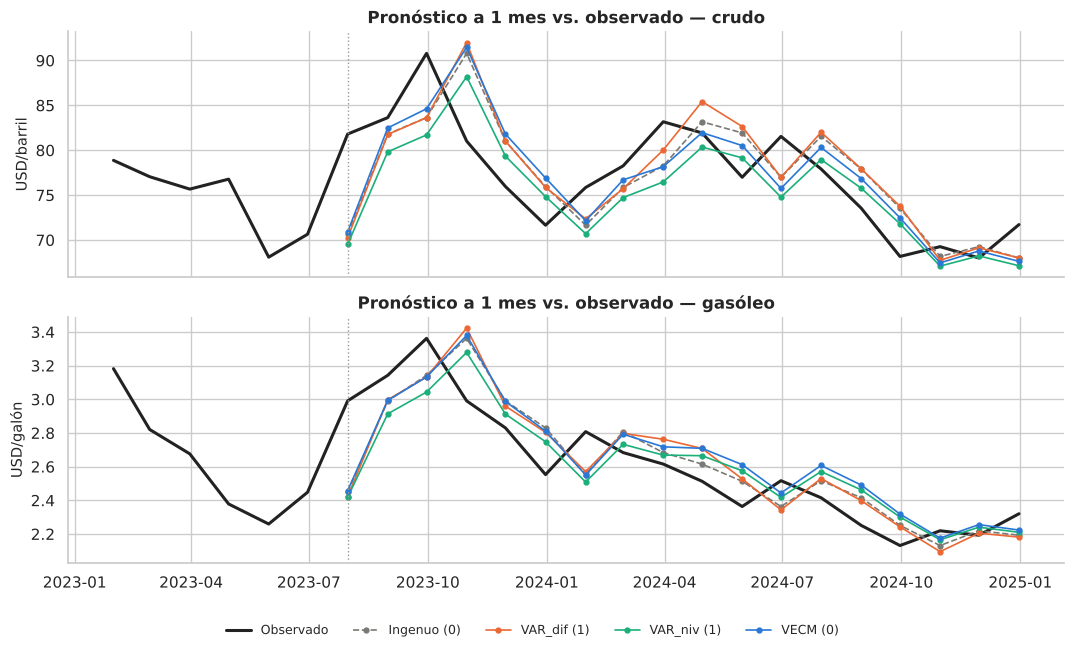

Diebold-Mariano h=1, VECM vs Ingenuo : estadístico = +1.64, p-valor = 0.120  (n = 18)
Diebold-Mariano h=1, VECM vs VAR_dif : estadístico = -0.38, p-valor = 0.707  (n = 18)
Diebold-Mariano h=1, VECM vs VAR_niv : estadístico = -0.05, p-valor = 0.959  (n = 18)


In [27]:
# Pronósticos a un mes frente a lo observado en el período de prueba
h1 = test[test["h"] == 1]
fig, axes = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)
for ax, (c, pc, nombre) in zip(axes, [("ln_CL", "pred_CL", "crudo"), ("ln_HO", "pred_HO", "gasóleo")]):
    obs = np.exp(datos.loc[INI_TEST - pd.DateOffset(months=6):, c])
    ax.plot(obs.index, obs, color=COL["obs"], lw=2.2, label="Observado")
    for mod in elegidos:
        d = h1[h1["modelo"] == mod]
        ax.plot(d["objetivo"], np.exp(d[pc]), color=COL[mod], marker="o", ms=3.5, lw=1.2,
                ls="--" if mod == "Ingenuo" else "-", label=f"{mod} ({elegidos[mod]})")
    ax.axvline(INI_TEST, color=COL["ref"], ls=":", lw=1)
    ax.set_ylabel("USD/barril" if c == "ln_CL" else "USD/galón")
    ax.set_title(f"Pronóstico a 1 mes vs. observado — {nombre}")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
manejadores, etiquetas = axes[0].get_legend_handles_labels()
fig.legend(manejadores, etiquetas, ncol=5, loc="lower center", fontsize=9, bbox_to_anchor=(0.5, -0.01))
plt.tight_layout(rect=(0, 0.05, 1, 1)); plt.show()

# Prueba de Diebold-Mariano (h = 1, pérdida cuadrática, promedio de las dos variables)
def diebold_mariano_h1(e_a, e_b):
    d = e_a - e_b
    est = d.mean() / np.sqrt(d.var(ddof=1) / len(d))
    return est, 2 * (1 - stats.t.cdf(abs(est), df=len(d) - 1))

perdida = h1.assign(l=(h1["e_CL"] ** 2 + h1["e_HO"] ** 2) / 2).pivot(index="objetivo", columns="modelo", values="l")
for rival in ("Ingenuo", "VAR_dif", "VAR_niv"):
    est, p = diebold_mariano_h1(perdida["VECM"], perdida[rival])
    print(f"Diebold-Mariano h=1, VECM vs {rival:<8}: estadístico = {est:+.2f}, p-valor = {p:.3f}  (n = {len(perdida)})")

**Interpretación de la evaluación final.**

- En el período de prueba (julio 2023 – diciembre 2024) **el VECM no supera al pronóstico ingenuo**: su RMSE promedio
  es ≈ 11 % mayor. El detalle importa: para el **crudo** el VECM es ligeramente mejor que el ingenuo, pero para el
  **gasóleo** es claramente peor y empeora con el horizonte.
- ¿Por qué? Durante 2024 el desequilibrio estimado se mantuvo positivo (≈ +0.10, crudo "caro" relativo al gasóleo)
  durante casi todo el año (gráfico del ECT, Módulo 7), algo incompatible con una semivida de 1.4 meses. El VECM esperaba
  que el gasóleo subiera para cerrar la brecha; en cambio siguió bajando, a medida que el margen de refinación de
  destilados se normalizaba tras los máximos de 2022. Es la misma inestabilidad que mostraron las estimaciones recursivas.
- El VAR en niveles obtiene los menores errores, sobre todo a 4-6 meses, en un período en que los precios oscilaron
  dentro de un rango y un modelo con reversión hacia una media fija se vio favorecido.
- A un mes, las diferencias entre modelos son pequeñas y la prueba de Diebold-Mariano no las distingue con
  significancia (con solo 18 pronósticos la potencia es muy baja).
- El orden de los modelos **cambió entre validación y prueba**: en validación el ingenuo fue el mejor y el VAR en niveles
  no destacó. Con muestras de evaluación tan cortas, las clasificaciones son inestables.

**Lección.** Un VECM puede ser la representación econométricamente correcta y la más interpretable (relación de
equilibrio, velocidades de ajuste, respuestas a choques) y, aun así, **no ser el mejor pronosticador**. Para precios de
materias primas, que están cerca de un paseo aleatorio, superar al modelo ingenuo es difícil. La afirmación del cuaderno
original de que "los pronósticos del VECM son superiores al VAR en diferencias" no está respaldada por estos datos.

### 10.3 Pronóstico de 2025 con el modelo final (ilustrativo, no evaluado)

Como ejemplo de uso, el VECM estimado con toda la muestra pronostica 12 meses. Los intervalos de `predict` suponen
errores gaussianos, supuesto que el diagnóstico rechazó: son **orientativos y probablemente demasiado estrechos** en
episodios extremos.

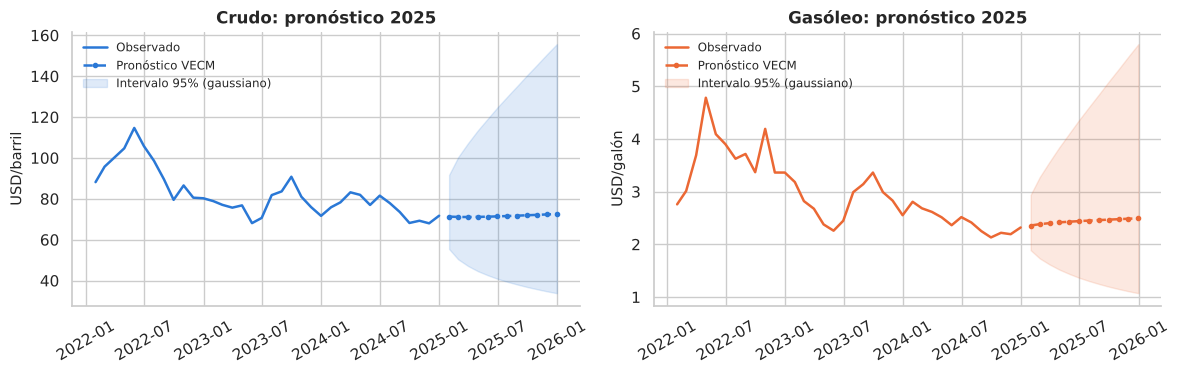

ln_CL                ln_HO            
             pron  inf95   sup95  pron inf95 sup95
2025-01-31  71.30  55.44   91.70  2.36  1.89  2.94
2025-03-31  71.08  47.10  107.28  2.40  1.62  3.57
2025-06-30  71.40  40.88  124.73  2.44  1.37  4.36
2025-12-31  72.55  33.81  155.68  2.50  1.07  5.80

In [28]:
H_FUT = 12
pred, inf, sup = vecm_res.predict(steps=H_FUT, alpha=0.05)
idx_fut = pd.date_range(datos.index[-1] + pd.offsets.MonthEnd(1), periods=H_FUT, freq="ME")
pron = {c: pd.DataFrame({"pron": np.exp(pred[:, j]), "inf95": np.exp(inf[:, j]), "sup95": np.exp(sup[:, j])}, index=idx_fut)
        for j, c in enumerate(cols)}

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for ax, c in zip(axes, cols):
    color = COL["CL"] if "CL" in c else COL["HO"]
    hist = mensual.iloc[-36:, cols.index(c)]
    ax.plot(hist.index, hist, color=color, label="Observado")
    ax.plot(idx_fut, pron[c]["pron"], color=color, ls="--", marker="o", ms=3, label="Pronóstico VECM")
    ax.fill_between(idx_fut, pron[c]["inf95"], pron[c]["sup95"], color=color, alpha=0.15, label="Intervalo 95% (gaussiano)")
    ax.set_title(f"{nombres_cortos[c].capitalize()}: pronóstico 2025"); ax.legend(loc="upper left", fontsize=8.5)
    ax.set_ylabel("USD/barril" if "CL" in c else "USD/galón")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m")); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
display(pd.concat(pron, axis=1).iloc[[0, 2, 5, 11]].round(2))

**Interpretación.** El pronóstico central cambia poco: el pequeño desequilibrio de diciembre de 2024 (crudo ≈ 5 % caro
relativo al gasóleo) se corrige principalmente con una subida del gasóleo y luego solo queda la deriva estimada. El
intervalo, en cambio, se ensancha con el horizonte, como corresponde a series $I(1)$: la incertidumbre crece sin límite.
Recuerde, además, que en 2024 el modelo esperó una corrección del gasóleo que no llegó. Nada en este gráfico ha sido
contrastado con datos de 2025.

> **Errores frecuentes.** (1) Estimar con toda la muestra y "evaluar" en el último año (filtración). (2) Elegir la
> configuración mirando el conjunto de prueba. (3) Comparar solo contra otro modelo complejo y no contra el ingenuo.
> (4) Transformar pronósticos log con $e^{\hat y}$ y llamarlos "esperanza": $e^{\hat y}$ aproxima la **mediana**, no la media.

> **Comprueba tu comprensión.** ¿Por qué la ventana expansiva reestima el modelo en cada origen en lugar de estimarlo
> una vez con los datos de entrenamiento?

---
## Módulo 11. Discusión económica

**Objetivo de aprendizaje:** redactar conclusiones que se sigan de los resultados y que expliciten su incertidumbre.

**¿Existe evidencia de una relación estable de largo plazo?** Sí, con matices. Ambas series se comportan como $I(1)$
(evidencia coherente con constante, no concluyente con tendencia). La prueba de Johansen rechaza la ausencia de
cointegración en todas las especificaciones con términos deterministas; el número de relaciones (1 frente a 2) es
dudoso al 5 % y se decidió $r=1$ con argumentos. La relación estimada, $\ln CL \approx 3.51 + 0.845\ln HO$, es estable
entre especificaciones y razonablemente estable en el tiempo. La homogeneidad estricta (elasticidad 1) se rechaza con la
muestra completa, pero no con la muestra previa a 2022; y en 2024 el desequilibrio persistió más de lo que el modelo
predice, lo que sugiere un posible desplazamiento de la relación tras 2022.

**¿Qué variables contribuyen al ajuste?** En la especificación principal ajusta el gasóleo: cuando el crudo está caro
relativo a él, el gasóleo sube; no se rechaza la exogeneidad débil del crudo. Esta conclusión **no es robusta**: con uno o
dos rezagos el patrón cambia. Lo robusto es que el sistema, en conjunto, corrige los desequilibrios ($\beta'\alpha<0$),
con una semivida del orden de uno a dos meses.

**¿Qué ocurre ante un choque?** Con identificación de Cholesky (crudo primero), un choque al crudo tiene efectos
permanentes sobre ambos precios y se transmite al gasóleo en pocos meses; los choques propios del gasóleo son en gran
parte transitorios. Las magnitudes dependen del orden de identificación, y no hay bandas de confianza.

**¿Qué tan sensible es el resultado?** $\beta$: poco sensible. $\alpha$, el rango y las IRF: sensibles a rezagos,
términos deterministas, orden de Cholesky y período muestral.

**¿Qué capacidad predictiva muestra?** Limitada: en la evaluación fuera de muestra el VECM no supera al paseo
aleatorio, y el mejor modelo cambió entre validación y prueba. La utilidad del VECM aquí es sobre todo **interpretativa**.

**Limitaciones.**

1. Muestra corta ($T=120$) y con choques extremos (2020, 2022); residuos no normales y con ARCH.
2. Futuros continuos con posibles efectos de empalme (por ejemplo, febrero de 2015).
3. Sistema bivariado: omite determinantes comunes (inventarios, márgenes de refinación, tipo de cambio, demanda) y otros
   refinados (gasolina), cuya inclusión podría cambiar $\beta$ y $\alpha$.
4. Las IRF y la FEVD dependen de una identificación recursiva sin bandas de confianza.
5. Cointegración describe un vínculo estadístico de largo plazo; **no identifica relaciones causales**.

**Cómo se diferencian asociación, cointegración y causalidad.** La correlación describe co-movimiento (y puede ser
espuria con series $I(1)$, Módulo 2); la cointegración afirma que una combinación lineal es estacionaria (equilibrio
estadístico); la causalidad exige un argumento de identificación adicional que este análisis no aporta.

---
## Módulo 12. Actividades de aprendizaje

Las actividades van de lo conceptual a lo aplicado. Las celdas de código vacías son para su trabajo.

### 12.1 Preguntas conceptuales
1. Explique con sus palabras por qué dos paseos aleatorios independientes pueden tener una correlación de 0.9.
2. ¿Qué diferencia hay entre "no rechazar la raíz unitaria" y "demostrar que la serie es I(1)"?
3. En un sistema de 3 variables con $r=1$, ¿cuántas tendencias estocásticas comunes hay? ¿Y con $r = 2$?

### 12.2 Interpretación de gráficos
4. En el gráfico del ECT (Módulo 7), identifique los dos períodos de mayor desequilibrio. Investigue qué ocurría en los
   mercados de crudo y destilados en esos meses y discuta si el desequilibrio es plausible económicamente.
5. En las estimaciones recursivas (Módulo 8), ¿en qué momento cambia más la elasticidad? ¿Qué evento lo explica?

### 12.3 Lectura de tablas
6. Con la tabla de Johansen del Módulo 6, escriba la secuencia de hipótesis, la decisión al 5 % y al 1 %, y explique por
   qué no se adoptó mecánicamente el resultado al 5 %.

### 12.4 Interpretación de $\alpha$ y $\beta$
7. Reordene las columnas (`datos[["ln_HO", "ln_CL"]]`), reestime el VECM y escriba la nueva relación de largo plazo.
   Muestre que es la misma relación con otra normalización y explique los nuevos signos de $\alpha$.
8. Calcule a mano el desequilibrio esperado al cabo de 3 meses si hoy $ECT = -0.15$.

### 12.5 Rezagos y sensibilidad
9. Repita el análisis con `k_ar_diff = 2` (AIC). Recalcule la "semivida" con la fórmula simple y explique por qué ya no es
   válida. Proponga cómo obtenerla a partir de la IRF del ECT.
10. Reestime el modelo con la muestra 2015-2019 (antes de la pandemia). ¿Qué conclusiones se mantienen?

### 12.6 Comparación VECM y VAR
11. Calcule la FEVD con el orden gasóleo → crudo y compárela con la del Módulo 9.
12. Agregue al Módulo 10 un VECM con `deterministic="ci"` y compare sus errores con el VECM principal.

### 12.7 Evaluación de pronósticos
13. Cambie el período de prueba a 2022-01 – 2023-06 (y la validación a un período anterior). ¿Se mantiene la
    clasificación de modelos? ¿Qué le dice eso sobre la confiabilidad de comparar modelos con 18 meses?
14. Agregue la métrica MAPE sobre precios (no logaritmos) y discuta si cambia alguna conclusión.

### 12.8 Reflexión
15. Un informe afirma: "el gasóleo corrige el 25 % del desequilibrio cada mes y el crudo causa al gasóleo". Señale cada
    error de interpretación usando los resultados de este cuaderno.

In [29]:
# Espacio para las actividades 12.1 - 12.8

### 12.9 Actividad integradora final

Elija **otro par (o trío) de series** con un argumento económico de equilibrio y desarrolle el análisis completo
reutilizando las funciones de este cuaderno. Opciones sugeridas (todas disponibles con `yfinance`):

| Opción | Series | Argumento económico |
|---|---|---|
| A | Crudo WTI (`CL=F`) y Brent (`BZ=F`) | Arbitraje entre dos marcadores del mismo bien |
| B | Crudo (`CL=F`) y gasolina RBOB (`RB=F`) | Margen de refinación de gasolina |
| C | Crudo, gasóleo y gasolina | Sistema de 3 variables: ¿cuántas relaciones de cointegración? |
| D | Oro (`GC=F`) y plata (`SI=F`) | Relación oro/plata (discuta si hay un argumento sólido) |

**Entregable (máximo 6 páginas o un cuaderno ejecutable):**

1. Pregunta económica y argumento de equilibrio.
2. Datos: fuente, período, frecuencia, faltantes, transformaciones, archivo congelado.
3. Orden de integración con ADF y KPSS (tabla y lectura conjunta).
4. Rezagos y prueba de Johansen con análisis de sensibilidad; decisión explícita sobre $r$.
5. Si $r\ge 1$: VECM, interpretación de $\beta$, $\alpha$ y semivida justificada. Si $r=0$: VAR en diferencias y discusión.
6. Diagnóstico con tabla de hallazgos.
7. IRF del modelo estimado, con discusión del orden de identificación.
8. Validación temporal con entrenamiento, validación y prueba, incluyendo el modelo ingenuo.
9. Conclusiones que distingan asociación, cointegración y causalidad, y una sección de limitaciones.

**Criterios de evaluación sugeridos:** corrección econométrica (35 %), coherencia entre resultados e interpretación (25 %),
diseño de la validación (20 %), claridad y reproducibilidad (20 %).

---
## Referencias

- Dickey, D. A., & Fuller, W. A. (1979). Distribution of the estimators for autoregressive time series with a unit root.
  *Journal of the American Statistical Association, 74*(366), 427–431.
- Diebold, F. X., & Mariano, R. S. (1995). Comparing predictive accuracy. *Journal of Business & Economic Statistics, 13*(3), 253–263.
- Engle, R. F., & Granger, C. W. J. (1987). Co-integration and error correction: Representation, estimation, and testing.
  *Econometrica, 55*(2), 251–276.
- Hamilton, J. D. (1994). *Time Series Analysis*. Princeton University Press. (Caps. 11, 17-19.)
- Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and Practice* (3.ª ed.). OTexts. https://otexts.com/fpp3/
- Johansen, S. (1988). Statistical analysis of cointegration vectors. *Journal of Economic Dynamics and Control, 12*(2–3), 231–254.
- Johansen, S. (1991). Estimation and hypothesis testing of cointegration vectors in Gaussian vector autoregressive
  models. *Econometrica, 59*(6), 1551–1580.
- Johansen, S. (1995). *Likelihood-Based Inference in Cointegrated Vector Autoregressive Models*. Oxford University Press.
- Johansen, S., & Juselius, K. (1990). Maximum likelihood estimation and inference on cointegration—with applications to
  the demand for money. *Oxford Bulletin of Economics and Statistics, 52*(2), 169–210.
- Juselius, K. (2006). *The Cointegrated VAR Model: Methodology and Applications*. Oxford University Press.
- Kwiatkowski, D., Phillips, P. C. B., Schmidt, P., & Shin, Y. (1992). Testing the null hypothesis of stationarity against
  the alternative of a unit root. *Journal of Econometrics, 54*(1–3), 159–178.
- Lütkepohl, H. (2005). *New Introduction to Multiple Time Series Analysis*. Springer. (Caps. 6-8.)
- Osterwald-Lenum, M. (1992). A note with quantiles of the asymptotic distribution of the maximum likelihood
  cointegration rank test statistics. *Oxford Bulletin of Economics and Statistics, 54*(3), 461–472.
- Seabold, S., & Perktold, J. (2010). statsmodels: Econometric and statistical modeling with Python. *Proceedings of the
  9th Python in Science Conference*, 92–96.
- Documentación de `statsmodels`: *Vector Error Correction Models (VECM)*,
  https://www.statsmodels.org/stable/vector_ar.html#vector-error-correction-models-vecm